# Questão 2 – Limites e continuidade

Investigue as funções definidas abaixo:

$$f_1(x,y) = \begin{cases}\dfrac{x^2 y}{x^2 + y^2}, & (x,y) \ne (0,0)\\[4pt] 0, & (x,y) = (0,0)\end{cases}
\qquad
f_2(x,y) = \begin{cases}\dfrac{xy}{x^2 + y^2}, & (x,y) \ne (0,0)\\[4pt] 0, & (x,y) = (0,0)\end{cases}$$

$$f_3(x,y) = \begin{cases}\dfrac{x^2 + y^2}{\sqrt{x^2 + y^2 + 1} + 1}, & (x,y) \ne (0,0)\\[4pt] 2, & (x,y) = (0,0)\end{cases}$$

A primeira célula de código abaixo carrega as bibliotecas e as funções auxiliares usadas em todos os itens. Rode-a antes das demais.

In [ ]:
# 💻 Configuração: bibliotecas, as três funções e auxiliares gerais
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import ipywidgets as widgets
from IPython.display import display, Markdown, clear_output

# Valor que o enunciado ATRIBUI a cada função na origem (o item 5 vai mexer só nisso)
VALOR_ORIGEM = {'f1': 0.0, 'f2': 0.0, 'f3': 2.0}


def _preparar(x, y):
    x, y = np.broadcast_arrays(np.asarray(x, dtype=float), np.asarray(y, dtype=float))
    return x, y, x**2 + y**2


def f1(x, y, valor_origem=None):
    """x²y/(x²+y²) fora da origem; na origem, o valor atribuído (padrão 0)."""
    x, y, r2 = _preparar(x, y)
    v0 = VALOR_ORIGEM['f1'] if valor_origem is None else valor_origem
    return np.divide(x**2 * y, r2, out=np.full_like(r2, v0), where=r2 > 0)


def f2(x, y, valor_origem=None):
    """xy/(x²+y²) fora da origem; na origem, o valor atribuído (padrão 0)."""
    x, y, r2 = _preparar(x, y)
    v0 = VALOR_ORIGEM['f2'] if valor_origem is None else valor_origem
    return np.divide(x * y, r2, out=np.full_like(r2, v0), where=r2 > 0)


def f3(x, y, valor_origem=None):
    """(x²+y²)/(√(x²+y²+1)+1) fora da origem; na origem, o valor atribuído (padrão 2)."""
    x, y, r2 = _preparar(x, y)
    v0 = VALOR_ORIGEM['f3'] if valor_origem is None else valor_origem
    return np.divide(r2, np.sqrt(r2 + 1) + 1, out=np.full_like(r2, v0), where=r2 > 0)


FUNCOES = {'f1': f1, 'f2': f2, 'f3': f3}

# Versões simbólicas (SymPy) da fórmula válida FORA da origem, para conferir as contas feitas na mão
xs_, ys_ = sp.symbols('x y', real=True)
EXPR = {
    'f1': xs_**2 * ys_ / (xs_**2 + ys_**2),
    'f2': xs_ * ys_ / (xs_**2 + ys_**2),
    'f3': (xs_**2 + ys_**2) / (sp.sqrt(xs_**2 + ys_**2 + 1) + 1),
}

---
## Item 1 – Visualização 3D e aproximação à origem por trajetórias

> **Enunciado:** Crie uma visualização 3D e simule a aproximação à origem por retas, parábolas e outras trajetórias.

**Ideia.** Para descobrir de que valor $f(x,y)$ se aproxima quando $(x,y) \to (0,0)$, "caminhamos" até a origem por uma curva

$$\gamma(t) = \big(x(t),\, y(t)\big), \qquad \gamma(t) \to (0,0) \text{ quando } t \to 0,$$

e observamos a altura $f(\gamma(t))$. Sobre a superfície $z = f(x,y)$, isso é andar pela curva $\big(x(t),\, y(t),\, f(x(t), y(t))\big)$. O parâmetro $t$ **nunca vale 0**: a origem é o destino, não um ponto do caminho. Por isso o valor atribuído $f(0,0)$ **não interfere** no que se observa ao longo das trajetórias.

**Trajetórias usadas**

| Trajetória | $\gamma(t)$ | Parâmetro |
|:---|:---:|:---:|
| Reta $y = mx$ | $(t,\ mt)$ | inclinação $m$ |
| Eixo $y$ ($x = 0$) | $(0,\ t)$ | — |
| Parábola $y = kx^2$ | $(t,\ kt^2)$ | $k$ |
| Parábola deitada $x = ky^2$ | $(kt^2,\ t)$ | $k$ |
| Espiral | $(t\cos\theta(t),\ t\sin\theta(t))$, com $\theta(t) = 6\ln(1/t)$ | — |

A espiral é a "outra trajetória": a distância até a origem é $t$, mas o ângulo $\theta(t) \to \infty$, então ela dá **infinitas voltas** em torno da origem enquanto se aproxima dela.

> ⚠️ Este item é **exploratório**. Ver o mesmo valor em várias trajetórias é evidência, não prova (item 3). A justificativa conclusiva fica para o item 2.

**Como este item está organizado**

1. 💻 **Configuração do item:** as trajetórias e as funções de desenho.
2. **Para cada função:**
   - ✍️ **análise na mão:** $f$ ao longo de cada trajetória, a forma polar e a superfície esperada;
   - 💻 **trajetórias fixas:** superfície 3D com várias trajetórias, o gráfico de $f(\gamma(t))$ quando $t \to 0$ e uma tabela de valores;
   - 💻 **conferência simbólica:** o SymPy refaz as substituições da análise na mão;
   - 💻 **explorador interativo:** você escolhe a trajetória e o parâmetro e leva o ponto até perto da origem.

**Convenção dos gráficos:** ponto **preto** = valor atribuído $(0,\,0,\,f(0,0))$; curvas coloridas = trajetórias sobre a superfície; ponto **vermelho** (explorador) = posição atual na trajetória.

In [36]:
# 💻 Configuração do item 1: trajetórias e funções de desenho
R_MAX = 1.0                                     # raio da região mostrada em volta da origem
T_TABELA = [1e-1, 1e-2, 1e-3, 1e-4, 1e-6]       # valores de t usados nas tabelas


def _espiral(t):
    """Distância à origem = t; ângulo θ(t) = 6·ln(1/t) -> ∞ (infinitas voltas)."""
    t = np.abs(t)
    theta = 6 * np.log(1 / t)
    return t * np.cos(theta), t * np.sin(theta)


# nome: (γ(t, p), nome do parâmetro p ou None, faz sentido usar t < 0?)
TRAJETORIAS = {
    'Reta y = m·x':      (lambda t, p: (t, p * t),          'm',  True),
    'Eixo y (x = 0)':    (lambda t, p: (0 * t, t),          None, True),
    'Parábola y = k·x²': (lambda t, p: (t, p * t**2),       'k',  True),
    'Parábola x = k·y²': (lambda t, p: (p * t**2, t),       'k',  True),
    'Espiral (r = t)':   (lambda t, p: _espiral(t),         None, False),
}


def rotulo(trajetoria, p):
    """'Reta y = m·x' com m = 2 -> 'Reta y = 2·x'."""
    nome_par = TRAJETORIAS[trajetoria][1]
    return trajetoria if nome_par is None else trajetoria.replace(f'{nome_par}·', f'{p:g}·')


def percorrer(nome_f, trajetoria, p, t):
    """Pontos γ(t) e alturas f(γ(t)). Os valores de t passados nunca incluem 0."""
    gamma = TRAJETORIAS[trajetoria][0]
    xs, ys = np.broadcast_arrays(*gamma(np.asarray(t, dtype=float), p))
    return xs, ys, FUNCOES[nome_f](xs, ys)


# ---------- peças dos gráficos 3D (Plotly)
def superficie_polar(nome_f, r_min=1e-3, n_r=90, n_t=145):
    """Malha polar: f1, f2 e f3 ficam simples em polares e a origem fica de fora (r >= r_min)."""
    r = np.linspace(r_min, R_MAX, n_r)
    th = np.linspace(0, 2 * np.pi, n_t)
    R, T = np.meshgrid(r, th)
    X, Y = R * np.cos(T), R * np.sin(T)
    return go.Surface(x=X, y=Y, z=FUNCOES[nome_f](X, Y), colorscale='Viridis', opacity=0.75,
                      showscale=False, name='z = f(x,y)', hovertemplate='x=%{x:.3f}<br>y=%{y:.3f}<br>z=%{z:.4f}')


def curva_na_superficie(nome_f, trajetoria, p, cor, nome=None):
    """A trajetória 'subindo' na superfície: (x(t), y(t), f(x(t), y(t))), dos dois lados quando faz sentido."""
    t = np.logspace(0.5, -4, 700)
    lados = [t, -t] if TRAJETORIAS[trajetoria][2] else [t]
    xs, ys, zs = [], [], []
    for tl in lados:
        x, y, z = percorrer(nome_f, trajetoria, p, tl)
        fora = np.hypot(x, y) > R_MAX            # só a parte dentro da região mostrada
        for lista, v in ((xs, x), (ys, y), (zs, z)):
            lista.extend(np.where(fora, np.nan, v).tolist() + [np.nan])
    return go.Scatter3d(x=xs, y=ys, z=zs, mode='lines', line=dict(color=cor, width=6),
                        name=nome or rotulo(trajetoria, p))


def ponto_origem(nome_f):
    v0 = VALOR_ORIGEM[nome_f]
    return go.Scatter3d(x=[0], y=[0], z=[v0], mode='markers', marker=dict(color='black', size=6),
                        name=f'valor atribuído: {nome_f}(0,0) = {v0:g}')


def mostrar_3d(tracos, titulo, altura=560):
    fig = go.Figure(tracos)
    fig.update_layout(title=titulo, height=altura, margin=dict(l=0, r=0, t=50, b=0),
                      legend=dict(x=0, y=1, bgcolor='rgba(255,255,255,0.7)'),
                      scene=dict(xaxis_title='x', yaxis_title='y', zaxis_title='z',
                                 aspectmode='manual', aspectratio=dict(x=1, y=1, z=0.7)))
    fig.show()


# ---------- painel com trajetórias fixas: 3D + gráfico de f(γ(t)) + tabela
def mostrar_trajetorias(nome_f, casos, titulo, extras=()):
    """casos = lista de (trajetória, parâmetro, cor)."""
    tracos = [superficie_polar(nome_f)]
    tracos += [curva_na_superficie(nome_f, tr, p, cor) for tr, p, cor in casos]
    tracos += [ponto_origem(nome_f), *extras]
    mostrar_3d(tracos, titulo)

    # Altura ao longo de cada trajetória quando t -> 0 (t > 0; eixo t em escala log, invertido)
    t = np.logspace(0, -6, 800)
    fig, ax = plt.subplots(figsize=(11, 4))
    for tr, p, cor in casos:
        ax.plot(t, percorrer(nome_f, tr, p, t)[2], color=cor, lw=2, label=rotulo(tr, p))
    ax.axhline(VALOR_ORIGEM[nome_f], color='black', ls='--', lw=1.2,
               label=f'valor atribuído {nome_f}(0,0) = {VALOR_ORIGEM[nome_f]:g}')
    ax.set_xscale('log')
    ax.invert_xaxis()
    ax.set_xlabel('t   (da esquerda para a direita, t → 0 e o ponto se aproxima da origem)')
    ax.set_ylabel(f'{nome_f}(γ(t))')
    ax.set_title(f'{nome_f} ao longo de cada trajetória')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc='center left', bbox_to_anchor=(1.01, 0.5))
    plt.tight_layout()
    plt.show()

    # Tabela
    print(f"{nome_f}(γ(t)) para t -> 0:\n")
    print(f"{'trajetória':<24}" + ''.join(f"{'t = ' + format(tt, 'g'):>14}" for tt in T_TABELA))
    for tr, p, _ in casos:
        valores = percorrer(nome_f, tr, p, T_TABELA)[2]
        print(f"{rotulo(tr, p):<24}" + ''.join(f"{v:>14.6f}" for v in valores))


# ---------- conferência simbólica das substituições feitas na mão
t_, m_, k_ = sp.symbols('t m k', real=True)
r_, th_ = sp.symbols('r theta', positive=True)
CASOS_SIMBOLICOS = [
    ('Reta $y = mx$',         {xs_: t_, ys_: m_ * t_},        t_),
    ('Eixo $y$',              {xs_: 0, ys_: t_},              t_),
    ('Parábola $y = kx^2$',   {xs_: t_, ys_: k_ * t_**2},     t_),
    ('Parábola $x = ky^2$',   {xs_: k_ * t_**2, ys_: t_},     t_),
    ('Polares $x = r\\cos\\theta,\\ y = r\\sin\\theta$',
                              {xs_: r_ * sp.cos(th_), ys_: r_ * sp.sin(th_)}, r_),
]


def conferencia_simbolica(nome_f, casos=None):
    casos = CASOS_SIMBOLICOS if casos is None else casos
    linhas = ['| Trajetória | $f(\\gamma)$ simplificada | Limite (variável $\\to 0$) |', '|:---|:---:|:---:|']
    for rot, subs, var in casos:
        expr = sp.simplify(sp.trigsimp(EXPR[nome_f].subs(subs, simultaneous=True)))
        lim = sp.simplify(sp.limit(expr, var, 0, '+'))
        linhas.append(f'| {rot} | ${sp.latex(expr)}$ | ${sp.latex(lim)}$ |')
    display(Markdown('\n'.join(linhas)))


# ---------- explorador interativo
def explorador(nome_f):
    traj = widgets.Dropdown(options=list(TRAJETORIAS), value='Reta y = m·x', description='Trajetória:',
                            layout=widgets.Layout(width='320px'))
    par = widgets.FloatSlider(value=1.0, min=-3, max=3, step=0.25, description='m:', continuous_update=False)
    lado = widgets.Dropdown(options=[('t > 0', 1), ('t < 0', -1)], value=1, description='Lado:',
                            layout=widgets.Layout(width='200px'))
    expo = widgets.IntSlider(value=1, min=0, max=6, description='t = ±10^(−p), p:', continuous_update=False,
                             style={'description_width': 'initial'}, layout=widgets.Layout(width='380px'))
    saida = widgets.Output()

    def atualizar(*_):
        _, nome_par, dois_lados = TRAJETORIAS[traj.value]
        par.disabled = nome_par is None
        if nome_par:
            par.description = nome_par + ':'
        lado.disabled = not dois_lados
        s = lado.value if dois_lados else 1
        t0 = s * 10.0 ** (-expo.value)
        x0, y0, z0 = (float(v[0]) for v in percorrer(nome_f, traj.value, par.value, [t0]))
        with saida:
            clear_output(wait=True)
            mostrar_3d([superficie_polar(nome_f),
                        curva_na_superficie(nome_f, traj.value, par.value, '#d62828'),
                        go.Scatter3d(x=[x0], y=[y0], z=[z0], mode='markers',
                                     marker=dict(color='red', size=7), name='posição atual γ(t)'),
                        ponto_origem(nome_f)],
                       f'{nome_f}: {rotulo(traj.value, par.value)}', altura=500)
            display(Markdown(
                f"| $t$ | $\\gamma(t)$ | distância até a origem | ${nome_f}(\\gamma(t))$ | valor atribuído ${nome_f}(0,0)$ |\n"
                f"|:---:|:---:|:---:|:---:|:---:|\n"
                f"| {t0:g} | ({x0:.3g}, {y0:.3g}) | {np.hypot(x0, y0):.3g} | **{z0:.8f}** | {VALOR_ORIGEM[nome_f]:g} |"))

    for w in (traj, par, lado, expo):
        w.observe(atualizar, names='value')
    atualizar()
    display(widgets.VBox([widgets.HBox([traj, par]), widgets.HBox([lado, expo]), saida]))

### $f_1(x,y) = \dfrac{x^2 y}{x^2 + y^2}$, com $f_1(0,0) = 0$

#### Análise na mão ✍️

**Passo 1: retas $y = mx$.** Substituindo $x = t$ e $y = mt$, com $t \ne 0$:

$$f_1(t,\, mt) = \frac{t^2 \cdot mt}{t^2 + m^2t^2} = \frac{m\,t^3}{t^2\,(1 + m^2)} = \frac{m}{1+m^2}\; t \;\xrightarrow{\;t \to 0\;}\; 0$$

Qualquer que seja a inclinação $m$, a altura vai a **0**. O eixo $y$ não é da forma $y = mx$ e precisa ser feito à parte, mas também dá 0: $f_1(0, t) = \dfrac{0}{t^2} = 0$.

**Passo 2: parábolas.**

$$f_1(t,\, kt^2) = \frac{t^2 \cdot kt^2}{t^2 + k^2t^4} = \frac{k\,t^2}{1 + k^2t^2} \to 0
\qquad\qquad
f_1(kt^2,\, t) = \frac{k^2t^4 \cdot t}{k^2t^4 + t^2} = \frac{k^2\,t^3}{k^2t^2 + 1} \to 0$$

**Passo 3: coordenadas polares e a espiral.** Com $x = r\cos\theta$, $y = r\sin\theta$ e $x^2 + y^2 = r^2$:

$$f_1 = \frac{r^2\cos^2\theta \cdot r\sin\theta}{r^2} = r\,\cos^2\theta\,\sin\theta$$

O fator $\cos^2\theta\,\sin\theta$ fica sempre entre $-1$ e $1$, então $|f_1| \le r$. Na espiral, $r = t$, logo $|f_1(\gamma(t))| \le t \to 0$, **mesmo com o ângulo dando infinitas voltas**.

**Passo 4: o que esperar.** Todas as trajetórias levam à altura **0**, que coincide com o valor atribuído $f_1(0,0) = 0$. Isso **sugere** que o limite é 0. A desigualdade $|f_1| \le r$ do passo 3 é exatamente a ideia que vai virar prova no item 2.

**Superfície esperada.** Pela forma polar, em cada direção $\theta$ a altura cresce **linearmente** com a distância $r$, com inclinação $\cos^2\theta\,\sin\theta$. A superfície é formada por segmentos de reta que saem de $(0,0,0)$, como um "cone ondulado":
- positiva onde $y > 0$ e negativa onde $y < 0$;
- nula sobre os eixos $x$ e $y$;
- perto da origem ela se **achata** até a altura 0, por qualquer direção.

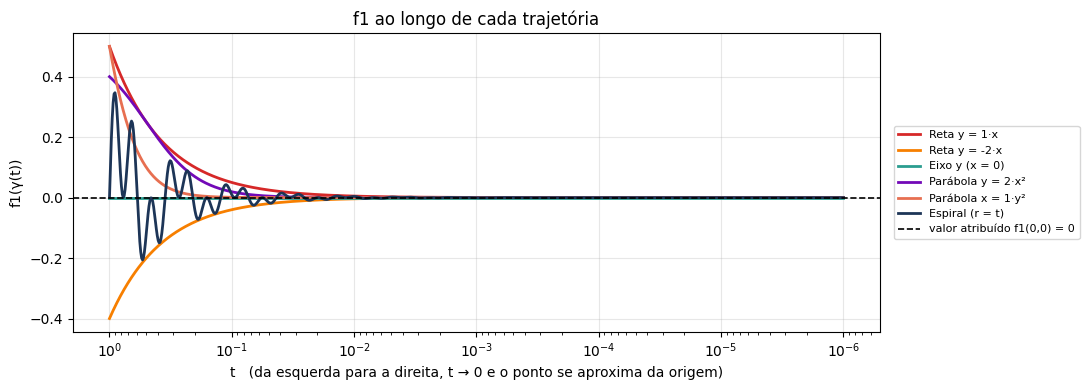

f1(γ(t)) para t -> 0:

trajetória                     t = 0.1      t = 0.01     t = 0.001    t = 0.0001     t = 1e-06
Reta y = 1·x                  0.050000      0.005000      0.000500      0.000050      0.000000
Reta y = -2·x                -0.040000     -0.004000     -0.000400     -0.000040     -0.000000
Eixo y (x = 0)                0.000000      0.000000      0.000000      0.000000      0.000000
Parábola y = 2·x²             0.019231      0.000200      0.000002      0.000000      0.000000
Parábola x = 1·y²             0.000990      0.000001      0.000000      0.000000      0.000000
Espiral (r = t)               0.009482      0.003840     -0.000385     -0.000008      0.000000


In [37]:
# 💻 f1: superfície e trajetórias fixas (arraste para girar)
CASOS_F1 = [
    ('Reta y = m·x',      1.0,  '#d62828'),
    ('Reta y = m·x',     -2.0,  '#f77f00'),
    ('Eixo y (x = 0)',    0,    '#2a9d8f'),
    ('Parábola y = k·x²', 2.0,  '#7209b7'),
    ('Parábola x = k·y²', 1.0,  '#e76f51'),
    ('Espiral (r = t)',   0,    '#1d3557'),
]
mostrar_trajetorias('f1', CASOS_F1, 'f1 = x²y/(x²+y²): todas as trajetórias descem até a altura 0')

In [38]:
# 💻 f1: conferência simbólica das substituições da análise na mão
conferencia_simbolica('f1')

| Trajetória | $f(\gamma)$ simplificada | Limite (variável $\to 0$) |
|:---|:---:|:---:|
| Reta $y = mx$ | $\frac{m t}{m^{2} + 1}$ | $0$ |
| Eixo $y$ | $0$ | $0$ |
| Parábola $y = kx^2$ | $\frac{k t^{2}}{k^{2} t^{2} + 1}$ | $0$ |
| Parábola $x = ky^2$ | $\frac{k^{2} t^{3}}{k^{2} t^{2} + 1}$ | $0$ |
| Polares $x = r\cos\theta,\ y = r\sin\theta$ | $r \sin{\left(\theta \right)} \cos^{2}{\left(\theta \right)}$ | $0$ |

In [39]:
# 💻 f1: explorador interativo (escolha a trajetória e aumente p para aproximar o ponto da origem)
explorador('f1')

### $f_2(x,y) = \dfrac{xy}{x^2 + y^2}$, com $f_2(0,0) = 0$

#### Análise na mão ✍️

**Passo 1: retas $y = mx$.** Com $x = t$, $y = mt$ e $t \ne 0$:

$$f_2(t,\, mt) = \frac{t \cdot mt}{t^2 + m^2t^2} = \frac{m\,t^2}{t^2\,(1 + m^2)} = \frac{m}{1 + m^2}$$

O $t$ **cancela por completo**: ao longo de cada reta, $f_2$ é **constante**. Mas a constante **depende da reta**:

| Trajetória | $m$ | $f_2$ ao longo dela |
|:---:|:---:|:---:|
| eixo $x$ | $0$ | $0$ |
| $y = x$ | $1$ | $\tfrac12$ |
| $y = -x$ | $-1$ | $-\tfrac12$ |
| $y = 2x$ | $2$ | $\tfrac25$ |
| eixo $y$ | — | $f_2(0,t) = 0$ |

**Passo 2: parábolas.**

$$f_2(t,\, kt^2) = \frac{k\,t^3}{t^2 + k^2t^4} = \frac{k\,t}{1 + k^2t^2} \to 0
\qquad\qquad
f_2(kt^2,\, t) = \frac{k\,t^3}{k^2t^4 + t^2} = \frac{k\,t}{k^2t^2 + 1} \to 0$$

As parábolas chegam em 0 porque elas chegam na origem **tangentes a um eixo**, e sobre os eixos $f_2 = 0$ (veja o passo 3).

**Passo 3: coordenadas polares e a espiral.**

$$f_2 = \frac{r\cos\theta \cdot r\sin\theta}{r^2} = \cos\theta\,\sin\theta = \frac{\sin 2\theta}{2}$$

$f_2$ **não depende de $r$**, só da **direção** $\theta$. Na espiral, $\theta(t) = 6\ln(1/t) \to \infty$, então

$$f_2(\gamma(t)) = \frac{\sin\big(2\theta(t)\big)}{2}$$

fica **oscilando entre $-\tfrac12$ e $\tfrac12$** e não se aproxima de valor nenhum.

**Passo 4: o que esperar.** Trajetórias diferentes dão valores diferentes ($0$, $\tfrac12$, $-\tfrac12$, $\tfrac25$, ...), e na espiral não há nem um valor final. Isso **indica** que o limite **não existe**. O item 2 transforma essa observação em argumento conclusivo.

**Superfície esperada.** Cada raio que sai da origem fica numa **altura constante** $\tfrac{\sin 2\theta}{2}$. A superfície é formada por segmentos **horizontais** que giram em torno do eixo $z$ e sobem e descem conforme a direção:
- máximo $\tfrac12$ sobre a reta $y = x$, mínimo $-\tfrac12$ sobre $y = -x$, zero sobre os eixos;
- todas as alturas entre $-\tfrac12$ e $\tfrac12$ "chegam" ao eixo $z$: perto da origem a superfície **não se aproxima de uma altura única**. O valor atribuído $f_2(0,0) = 0$ é apenas uma dessas alturas (segmento tracejado no gráfico).

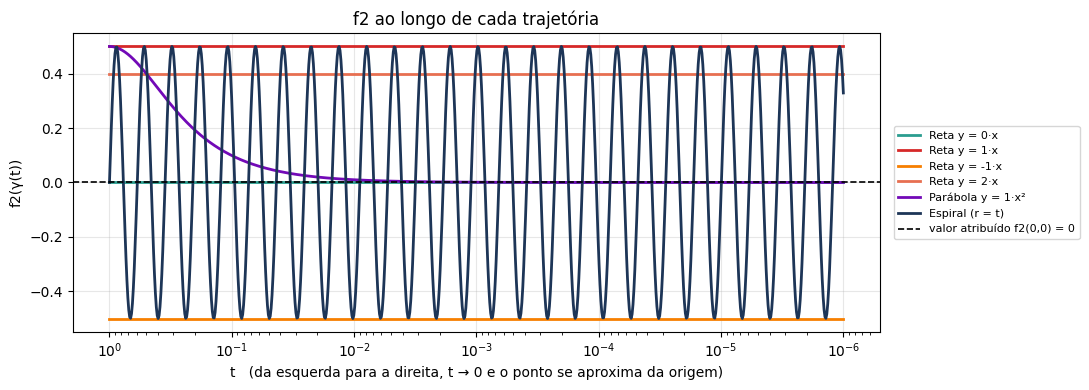

f2(γ(t)) para t -> 0:

trajetória                     t = 0.1      t = 0.01     t = 0.001    t = 0.0001     t = 1e-06
Reta y = 0·x                  0.000000      0.000000      0.000000      0.000000      0.000000
Reta y = 1·x                  0.500000      0.500000      0.500000      0.500000      0.500000
Reta y = -1·x                -0.500000     -0.500000     -0.500000     -0.500000     -0.500000
Reta y = 2·x                  0.400000      0.400000      0.400000      0.400000      0.400000
Parábola y = 1·x²             0.099010      0.009999      0.001000      0.000100      0.000001
Espiral (r = t)               0.299925     -0.479947      0.468099     -0.269118      0.329047


In [40]:
# 💻 f2: superfície e trajetórias fixas (arraste para girar)
CASOS_F2 = [
    ('Reta y = m·x',      0.0,  '#2a9d8f'),
    ('Reta y = m·x',      1.0,  '#d62828'),
    ('Reta y = m·x',     -1.0,  '#f77f00'),
    ('Reta y = m·x',      2.0,  '#e76f51'),
    ('Parábola y = k·x²', 1.0,  '#7209b7'),
    ('Espiral (r = t)',   0,    '#1d3557'),
]
# Segmento vertical sobre a origem: todas as alturas de -1/2 a 1/2 se acumulam ali
acumulo = go.Scatter3d(x=[0, 0], y=[0, 0], z=[-0.5, 0.5], mode='lines',
                       line=dict(color='black', width=4, dash='dash'),
                       name='alturas que se acumulam na origem: [−1/2, 1/2]')
mostrar_trajetorias('f2', CASOS_F2, 'f2 = xy/(x²+y²): cada reta chega numa altura diferente', extras=[acumulo])

In [41]:
# 💻 f2: conferência simbólica das substituições da análise na mão
conferencia_simbolica('f2')

| Trajetória | $f(\gamma)$ simplificada | Limite (variável $\to 0$) |
|:---|:---:|:---:|
| Reta $y = mx$ | $\frac{m}{m^{2} + 1}$ | $\frac{m}{m^{2} + 1}$ |
| Eixo $y$ | $0$ | $0$ |
| Parábola $y = kx^2$ | $\frac{k t}{k^{2} t^{2} + 1}$ | $0$ |
| Parábola $x = ky^2$ | $\frac{k t}{k^{2} t^{2} + 1}$ | $0$ |
| Polares $x = r\cos\theta,\ y = r\sin\theta$ | $\frac{\sin{\left(2 \theta \right)}}{2}$ | $\frac{\sin{\left(2 \theta \right)}}{2}$ |

In [42]:
# 💻 f2: explorador interativo (mude m e veja a altura de chegada mudar; teste a espiral)
explorador('f2')

### $f_3(x,y) = \dfrac{x^2 + y^2}{\sqrt{x^2 + y^2 + 1} + 1}$, com $f_3(0,0) = 2$

#### Análise na mão ✍️

**Passo 1: $f_3$ só depende da distância.** Com $r^2 = x^2 + y^2$:

$$f_3 = \frac{r^2}{\sqrt{r^2 + 1} + 1}$$

Não aparece $\theta$: a direção não importa, só a distância até a origem.

**Passo 2: retas, parábolas e espiral.** Basta saber o que acontece com $r^2$ em cada trajetória:

| Trajetória | $r^2 = x(t)^2 + y(t)^2$ | quando $t \to 0$ |
|:---:|:---:|:---:|
| reta $y = mx$ | $(1 + m^2)\,t^2$ | $\to 0$ |
| eixo $y$ | $t^2$ | $\to 0$ |
| parábola $y = kx^2$ | $t^2 + k^2t^4$ | $\to 0$ |
| parábola $x = ky^2$ | $k^2t^4 + t^2$ | $\to 0$ |
| espiral | $t^2$ | $\to 0$ |

Em todos os casos o numerador vai a 0 e o denominador vai a $\sqrt{0 + 1} + 1 = 2$, então

$$f_3(\gamma(t)) \to \frac{0}{2} = 0$$

**Passo 3: uma forma mais simples (racionalização).** Multiplicando numerador e denominador por $\sqrt{r^2 + 1} - 1$:

$$f_3 = \frac{r^2\,\big(\sqrt{r^2+1} - 1\big)}{\big(\sqrt{r^2+1}+1\big)\big(\sqrt{r^2+1}-1\big)} = \frac{r^2\,\big(\sqrt{r^2+1} - 1\big)}{(r^2 + 1) - 1} = \sqrt{r^2 + 1} - 1, \qquad r \ne 0$$

Nessa forma é ainda mais direto: quando $r \to 0$, $f_3 \to \sqrt{1} - 1 = 0$.

**Passo 4: o que esperar.** Todas as trajetórias levam à altura **0**. Mas o valor atribuído é $f_3(0,0) = 2 \ne 0$. O item 1 já mostra esse **descompasso**; a conclusão sobre continuidade fica para o item 4.

**Superfície esperada.** $z = \sqrt{r^2 + 1} - 1$ é uma **tigela** que cresce suavemente a partir de $(0,0,0)$ (para $r$ pequeno, $z \approx r^2/2$, quase um paraboloide). Ela é a folha de cima do hiperboloide $(z+1)^2 - r^2 = 1$, deslocada 1 unidade para baixo. No fundo da tigela, $(0,0,0)$, há um **"buraco"**: a função na origem vale 2, um ponto isolado **flutuando acima** da superfície.

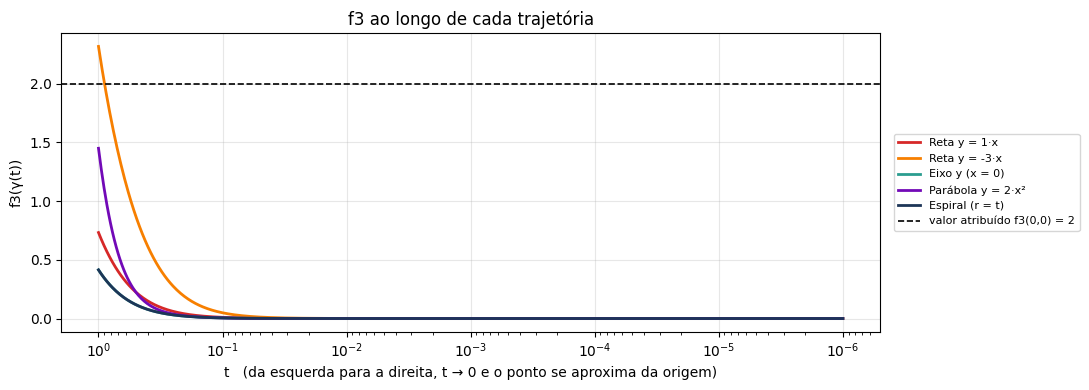

f3(γ(t)) para t -> 0:

trajetória                     t = 0.1      t = 0.01     t = 0.001    t = 0.0001     t = 1e-06
Reta y = 1·x                  0.009950      0.000100      0.000001      0.000000      0.000000
Reta y = -3·x                 0.048809      0.000500      0.000005      0.000000      0.000000
Eixo y (x = 0)                0.004988      0.000050      0.000000      0.000000      0.000000
Parábola y = 2·x²             0.005187      0.000050      0.000001      0.000000      0.000000
Espiral (r = t)               0.004988      0.000050      0.000000      0.000000      0.000000


In [43]:
# 💻 f3: superfície e trajetórias fixas (arraste para girar)
CASOS_F3 = [
    ('Reta y = m·x',      1.0,  '#d62828'),
    ('Reta y = m·x',     -3.0,  '#f77f00'),
    ('Eixo y (x = 0)',    0,    '#2a9d8f'),
    ('Parábola y = k·x²', 2.0,  '#7209b7'),
    ('Espiral (r = t)',   0,    '#1d3557'),
]
# Bolinha aberta em (0,0,0): para onde as trajetórias apontam (e que NÃO é o valor da função)
buraco = go.Scatter3d(x=[0], y=[0], z=[0], mode='markers',
                      marker=dict(color='white', size=6, symbol='circle-open', line=dict(color='black', width=3)),
                      name='altura para onde as trajetórias vão: 0')
mostrar_trajetorias('f3', CASOS_F3, 'f3: todas as trajetórias vão a 0, mas f3(0,0) = 2', extras=[buraco])

In [ ]:
# 💻 f3: conferência simbólica das substituições da análise na mão
conferencia_simbolica('f3')

In [45]:
# 💻 f3: explorador interativo (por qualquer trajetória a altura vai a 0, longe do ponto preto em z = 2)
explorador('f3')

---
## Item 2 – Existência do limite em $(0,0)$

> **Enunciado:** Investigue a existência do limite em $(0,0)$ e apresente uma justificativa matemática conclusiva.

**A definição.** Dizemos que $\displaystyle\lim_{(x,y)\to(0,0)} f(x,y) = L$ quando, para todo $\varepsilon > 0$, existe $\delta > 0$ tal que

$$0 < \sqrt{x^2 + y^2} < \delta \quad\Longrightarrow\quad |f(x,y) - L| < \varepsilon.$$

Em palavras: dá para garantir que $f$ fica **tão perto de $L$ quanto se queira** ($\varepsilon$), desde que o ponto esteja **perto o bastante da origem** ($\delta$), **qualquer que seja a direção ou o caminho**. O "$0 <$" exclui a própria origem: o valor $f(0,0)$ **não participa** da definição do limite.

**Ferramentas para uma justificativa conclusiva**

| Objetivo | Ferramenta | Por que é conclusiva |
|:---|:---|:---|
| provar que o limite **não existe** | **dois caminhos** com limites diferentes | se o limite fosse $L$, **todo** caminho teria de dar $L$ |
| provar que o limite **existe** | **confronto**: $\lvert f(x,y) - L\rvert \le g(x,y)$ com $g \to 0$ | a desigualdade vale em **todos** os pontos perto da origem, não só em alguns caminhos |
| provar que o limite **existe** | **ε-δ** direto (em geral, consequência do confronto) | é a própria definição |

Observar trajetórias, como no item 1, nunca prova que o limite **existe**: há infinitos caminhos e só conseguimos testar alguns (item 3). Já para provar que **não existe**, dois caminhos bastam.

**Como este item está organizado**

1. 💻 **Configuração do item:** o maior valor de $|f - L|$ em círculos ao redor da origem e o verificador ε-δ.
2. **Para cada função:**
   - ✍️ **análise na mão:** a prova (confronto e ε-δ, ou dois caminhos);
   - 💻 **conferência do limitante:** em círculos de raio $r \to 0$, compara o maior $|f - L|$ com o limitante usado na prova, e o SymPy confere as contas;
   - 💻 **verificador ε-δ interativo:** escolha $\varepsilon$ e veja se o $\delta$ da prova funciona.
3. **Conclusão do item.**

**Convenção dos gráficos ε-δ:** verde = pontos com $|f - L| < \varepsilon$; vermelho = pontos com $|f - L| \ge \varepsilon$; círculo preto = raio $\delta$; bolinha aberta = a origem, excluída; **×** = o pior ponto encontrado dentro do disco.

> ⚠️ Os testes numéricos abaixo são **conferências** das provas. A garantia vem das desigualdades feitas na mão, que valem para **todos** os pontos, e não só para os pontos amostrados.

In [ ]:
# 💻 Configuração do item 2: limitantes em círculos e verificador ε-δ
from matplotlib.colors import ListedColormap

ANGULOS = np.linspace(0, 2 * np.pi, 3601)
RAIOS = [1, 1e-1, 1e-2, 1e-3, 1e-4]


def valores_no_circulo(nome_f, r):
    """Valores de f no círculo de raio r em volta da origem (3601 ângulos)."""
    return FUNCOES[nome_f](r * np.cos(ANGULOS), r * np.sin(ANGULOS))


def maximo_no_circulo(nome_f, r, L):
    return np.max(np.abs(valores_no_circulo(nome_f, r) - L))


def conferir_limitante(nome_f, L, limitante, texto_limitante):
    """Tabela e gráfico: maior |f − L| no círculo de raio r, comparado com o limitante da prova."""
    print(f"Maior valor de |{nome_f} − L| (L = {L:g}) no círculo de raio r:\n")
    print(f"{'r':>10}{'máx |f − L|':>16}{'limitante ' + texto_limitante:>18}{'máx ≤ limitante?':>19}")
    for r in RAIOS:
        m, lim = maximo_no_circulo(nome_f, r, L), limitante(r)
        print(f"{r:>10g}{m:>16.4e}{lim:>18.4e}{('sim' if m <= lim else 'NÃO'):>19}")

    rr = np.logspace(0, -4, 60)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.loglog(rr, [maximo_no_circulo(nome_f, r, L) for r in rr], 'o-', ms=3, color='#2374d8',
              label=f'máx |{nome_f} − {L:g}| no círculo de raio r (amostrado)')
    ax.loglog(rr, limitante(rr), 'k--', label=f'limitante da prova: {texto_limitante}')
    ax.invert_xaxis()
    ax.set_xlabel('raio r do círculo   (r → 0 para a direita)')
    ax.set_ylabel(f'máx |{nome_f} − L|')
    ax.set_title(f'{nome_f}: quanto f se afasta de L = {L:g} perto da origem')
    ax.grid(alpha=0.3, which='both')
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


def _disco_furado(delta, n_r=160, n_t=721):
    """Pontos com 0 < r < δ (a origem fica de fora, como na definição).
    Além dos ângulos uniformes, inclui ângulos muito próximos dos eixos: curvas como y = x²
    chegam à origem quase coladas no eixo x e escapariam de uma amostragem só uniforme."""
    r = delta * np.linspace(1e-3, 1 - 1e-9, n_r)
    perto = np.logspace(-9, -1, 120)
    eixos = np.arange(4) * np.pi / 2
    th = np.unique(np.concatenate([np.linspace(0, 2 * np.pi, n_t),
                                   (eixos[:, None] + perto).ravel(), (eixos[:, None] - perto).ravel()]))
    R, T = np.meshgrid(r, th)
    return R * np.cos(T), R * np.sin(T)


def _desenhar_eps_delta(nome_f, L, eps, delta, pior):
    lado = 1.5 * delta
    g = np.linspace(-lado, lado, 401)
    GX, GY = np.meshgrid(g, g)
    dentro_eps = np.abs(FUNCOES[nome_f](GX, GY) - L) < eps
    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    ax.imshow(dentro_eps, extent=[-lado, lado, -lado, lado], origin='lower',
              cmap=ListedColormap(['#f4a3a3', '#a8d5a2']), vmin=0, vmax=1)
    ax.add_patch(plt.Circle((0, 0), delta, fill=False, lw=2, color='black'))
    ax.plot(0, 0, 'o', mfc='white', mec='black', ms=9)
    ok = pior[2] < eps
    ax.plot(pior[0], pior[1], 'x', color='black' if ok else 'red', ms=12, mew=3)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_title(f'{nome_f}: verde = |f − {L:g}| < ε = {eps:.3g};  círculo: δ = {delta:.3g}', fontsize=10)
    plt.tight_layout()
    plt.show()


def pior_ponto(nome_f, L, delta):
    """Ponto do disco furado 0 < r < δ (amostrado) onde |f − L| é maior."""
    X, Y = _disco_furado(delta)
    Z = np.abs(FUNCOES[nome_f](X, Y) - L)
    i = np.argmax(Z)
    return X.flat[i], Y.flat[i], Z.flat[i]


def verificador_eps_delta(nome_f, L=0.0, formula_delta=None, texto_delta=''):
    """Com formula_delta: usa o δ da prova (vezes um fator escolhido pelo usuário).
    Sem formula_delta (caso em que o limite não existe): o usuário escolhe δ e o L candidato."""
    estilo = {'description_width': 'initial'}
    eps = widgets.FloatLogSlider(value=0.1, base=10, min=-3, max=0, step=0.25, description='ε:',
                                 readout_format='.3g', continuous_update=False)
    if formula_delta is not None:
        fator = widgets.FloatSlider(value=1.0, min=0.5, max=4, step=0.25, continuous_update=False,
                                    description='δ usado = fator × δ da prova; fator:', style=estilo,
                                    layout=widgets.Layout(width='420px'))
        controles = [eps, fator]
    else:
        eps.value = 0.25
        delta_w = widgets.FloatLogSlider(value=0.1, base=10, min=-4, max=0, step=0.25, description='δ:',
                                         readout_format='.3g', continuous_update=False)
        L_w = widgets.FloatSlider(value=L, min=min(-1, L - 1), max=max(1, L + 1), step=0.05, description='L candidato:',
                                  style=estilo, continuous_update=False)
        controles = [eps, delta_w, L_w]
    saida = widgets.Output()

    def atualizar(*_):
        e = eps.value
        if formula_delta is not None:
            d_prova = formula_delta(e)
            d, Lc = fator.value * d_prova, L
        else:
            d, Lc = delta_w.value, L_w.value
        p = pior_ponto(nome_f, Lc, d)
        ok = p[2] < e
        with saida:
            clear_output(wait=True)
            _desenhar_eps_delta(nome_f, Lc, e, d, p)
            texto = []
            if formula_delta is not None:
                texto.append(f"δ da prova: ${texto_delta}$ = {d_prova:.4g}  →  δ usado = {fator.value:g} × {d_prova:.4g} = **{d:.4g}**")
            texto.append(f"Pior ponto amostrado em $0 < r < \\delta$: ({p[0]:.3g}, {p[1]:.3g}), "
                         f"com $|{nome_f} - L|$ = **{p[2]:.4g}**")
            if ok:
                texto.append(f"✅ {p[2]:.4g} < ε = {e:.3g}: dentro do disco, todos os pontos testados estão a menos de ε de L.")
            else:
                texto.append(f"❌ {p[2]:.4g} ≥ ε = {e:.3g}: há pontos dentro do disco com $|{nome_f} - L| \\ge \\varepsilon$. Esse δ não serve.")
            display(Markdown('  \n'.join(texto)))

    for w in controles:
        w.observe(atualizar, names='value')
    atualizar()
    display(widgets.VBox([widgets.HBox(controles), saida]))

### $f_1(x,y) = \dfrac{x^2 y}{x^2 + y^2}$, com $f_1(0,0) = 0$

#### Análise na mão ✍️

**Passo 1: o candidato.** Pelo item 1, todas as trajetórias testadas levam a 0. O candidato é $L = 0$. Agora é preciso **provar**.

**Passo 2: uma estimativa que vale em todos os pontos.** Para $(x,y) \ne (0,0)$, o numerador da fração $\dfrac{x^2}{x^2+y^2}$ nunca passa do denominador, porque $x^2 \le x^2 + y^2$. Logo

$$0 \le \frac{x^2}{x^2 + y^2} \le 1.$$

Então

$$|f_1(x,y) - 0| = \frac{x^2}{x^2 + y^2}\,|y| \;\le\; |y| \;\le\; \sqrt{x^2 + y^2}.$$

O último passo vale porque $y^2 \le x^2 + y^2$.

**Passo 3: confronto.**

$$0 \;\le\; |f_1(x,y)| \;\le\; \sqrt{x^2 + y^2}.$$

Quando $(x,y) \to (0,0)$, os dois lados vão a 0, então $|f_1| \to 0$, ou seja, $f_1 \to 0$.

**Passo 4: a definição ε-δ.** Dado $\varepsilon > 0$, tome $\delta = \varepsilon$. Se $0 < \sqrt{x^2 + y^2} < \delta$, então pelo passo 2

$$|f_1(x,y) - 0| \le \sqrt{x^2 + y^2} < \delta = \varepsilon. \qquad \blacksquare$$

**Por que isto é conclusivo, e as trajetórias não eram.** A desigualdade $|f_1| \le \sqrt{x^2+y^2}$ usa **só a distância** até a origem. Ela vale em **todo ponto** do disco de raio $\delta$, venha ele de reta, parábola, espiral ou qualquer outro caminho.

**O mesmo em polares.** $|f_1| = r\,|\cos^2\theta\,\sin\theta| \le r$. O que torna a prova válida é o limitante $r$ **não depender de $\theta$**. Uma forma polar $r \cdot g(\theta)$ só garante limite 0 quando $g$ é **limitada**. Aqui o maior valor de $|\cos^2\theta \sin\theta|$ é $\tfrac{2\sqrt3}{9} \approx 0{,}385$, então a estimativa $\le r$ tem até folga.

$$\boxed{\lim_{(x,y)\to(0,0)} f_1(x,y) = 0}$$

Maior valor de |f1 − L| (L = 0) no círculo de raio r:

         r     máx |f − L|       limitante r   máx ≤ limitante?
         1      3.8490e-01        1.0000e+00                sim
       0.1      3.8490e-02        1.0000e-01                sim
      0.01      3.8490e-03        1.0000e-02                sim
     0.001      3.8490e-04        1.0000e-03                sim
    0.0001      3.8490e-05        1.0000e-04                sim


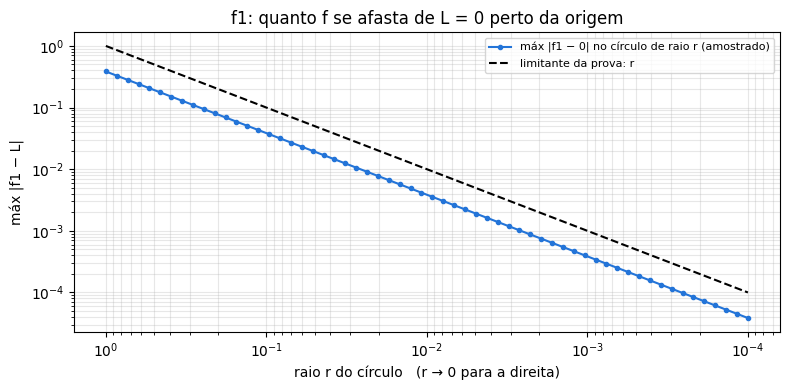


máx |cos²θ·sinθ| = 2*sqrt(3)/9 ≈ 0.3849 ≤ 1  ->  |f1| = r·|cos²θ·sinθ| ≤ 0.385·r ≤ r


In [47]:
# 💻 f1: conferência do limitante |f1| ≤ r
conferir_limitante('f1', L=0, limitante=lambda r: r, texto_limitante='r')

# SymPy: o maior valor de |cos²θ·sinθ| (o fator angular da forma polar)
fator_ang = sp.cos(th_)**2 * sp.sin(th_)          # th_ = símbolo θ (item 1)
criticos = sp.solve(sp.diff(fator_ang, th_), th_)
maior = max((sp.nsimplify(sp.simplify(sp.Abs(fator_ang.subs(th_, c)))) for c in criticos), key=float)
print(f"\nmáx |cos²θ·sinθ| = {maior} ≈ {float(maior):.4f} ≤ 1  ->  |f1| = r·|cos²θ·sinθ| ≤ {float(maior):.3f}·r ≤ r")

In [48]:
# 💻 f1: verificador ε-δ (com fator 1, o δ = ε da prova sempre funciona; aumente o fator para ver o disco ficar grande demais)
verificador_eps_delta('f1', L=0, formula_delta=lambda e: e, texto_delta=r'\delta = \varepsilon')

### $f_2(x,y) = \dfrac{xy}{x^2 + y^2}$, com $f_2(0,0) = 0$

#### Análise na mão ✍️

**Passo 1: se o limite existisse, todo caminho daria o mesmo valor.** Suponha que $\displaystyle\lim_{(x,y)\to(0,0)} f_2 = L$. Tome qualquer caminho $\gamma(t) \to (0,0)$ com $\gamma(t) \ne (0,0)$. Dado $\varepsilon > 0$, existe o $\delta$ da definição, e para $t$ pequeno o ponto $\gamma(t)$ está a menos de $\delta$ da origem. Então $|f_2(\gamma(t)) - L| < \varepsilon$. Ou seja, $f_2(\gamma(t)) \to L$ **ao longo de todo caminho**.

**Passo 2: dois caminhos com limites diferentes.**

- Eixo $x$, $\gamma(t) = (t, 0)$: $\quad f_2(t, 0) = \dfrac{0}{t^2} = 0 \;\to\; 0$. Pelo passo 1, $L = 0$.
- Reta $y = x$, $\gamma(t) = (t, t)$: $\quad f_2(t, t) = \dfrac{t^2}{2t^2} = \dfrac12 \;\to\; \dfrac12$. Pelo passo 1, $L = \dfrac12$.

Mas $L$ não pode valer $0$ e $\tfrac12$ ao mesmo tempo. **Contradição**: o limite não existe. $\blacksquare$

**Passo 3: a mesma coisa vista pela definição ε-δ.** Todo disco em volta da origem, por menor que seja o $\delta$, contém pontos da reta $y = x$ (onde $f_2 = \tfrac12$) e da reta $y = -x$ (onde $f_2 = -\tfrac12$). Para qualquer candidato $L$,

$$\Big|\tfrac12 - L\Big| + \Big|{-\tfrac12} - L\Big| \;\ge\; \Big|\tfrac12 - \big({-\tfrac12}\big)\Big| = 1,$$

então pelo menos uma das duas distâncias é $\ge \tfrac12$. Com $\varepsilon = \tfrac12$ (ou menor), **nenhum $\delta$ funciona, para nenhum $L$**. A definição de limite exige que funcione para **todo** $\varepsilon$, então falha.

**Por que a forma polar não salva.** $f_2 = \tfrac{\sin 2\theta}{2}$ não depende de $r$. Em **cada** círculo em volta da origem, por menor que seja, $f_2$ assume todos os valores de $-\tfrac12$ a $\tfrac12$. Não existe limitante que vá a 0.

**Observação.** O valor atribuído $f_2(0,0) = 0$ não entra em nada disso. O limite não existe **seja qual for** o valor na origem (itens 4 e 5).

$$\boxed{\lim_{(x,y)\to(0,0)} f_2(x,y) \text{ não existe}}$$

In [ ]:
# 💻 f2: em todo círculo, por menor que seja, f2 vai de −1/2 a 1/2
print("Menor e maior valor de f2 no círculo de raio r:\n")
print(f"{'r':>10}{'mín f2':>12}{'máx f2':>12}")
for r in RAIOS:
    v = valores_no_circulo('f2', r)
    print(f"{r:>10g}{v.min():>12.6f}{v.max():>12.6f}")
print("\nA oscilação não diminui quando r -> 0: não há limitante que vá a zero.\n")

# SymPy: os dois caminhos da prova
expr = EXPR['f2']      # usa os símbolos xs_, ys_ (configuração geral) e t_ (item 1)
print("Eixo x:    lim f2(t, 0) =", sp.limit(expr.subs({xs_: t_, ys_: 0}), t_, 0))
print("Reta y=x:  lim f2(t, t) =", sp.limit(expr.subs({xs_: t_, ys_: t_}), t_, 0))

In [50]:
# 💻 f2: verificador ε-δ. Escolha δ e o L candidato: com ε ≤ 1/2, nenhuma combinação deixa o disco todo verde.
verificador_eps_delta('f2', L=0)

### $f_3(x,y) = \dfrac{x^2 + y^2}{\sqrt{x^2 + y^2 + 1} + 1}$, com $f_3(0,0) = 2$

#### Análise na mão ✍️

**Passo 1: o candidato.** Pelo item 1, todas as trajetórias levam a 0. O candidato é $L = 0$.

**Passo 2: estimativa por confronto.** Como $\sqrt{x^2 + y^2 + 1} \ge \sqrt{1} = 1$, o denominador é pelo menos $1 + 1 = 2$. Dividir por um número maior dá um resultado menor:

$$0 \;\le\; f_3(x,y) = \frac{x^2 + y^2}{\sqrt{x^2 + y^2 + 1} + 1} \;\le\; \frac{x^2 + y^2}{2}.$$

Quando $(x,y) \to (0,0)$, o lado direito vai a 0. Pelo confronto, $f_3 \to 0$.

**Passo 3: outro argumento, por continuidade.** Pela racionalização do item 1, para $(x,y) \ne (0,0)$,

$$f_3(x,y) = \sqrt{x^2 + y^2 + 1} - 1 =: g(x,y).$$

A função $g$ está definida e é **contínua em todo o plano**: é uma raiz de um polinômio que é sempre $\ge 1$, menos 1. O limite só olha os pontos **diferentes da origem**, e nesses pontos $f_3 = g$. Logo

$$\lim_{(x,y)\to(0,0)} f_3 = \lim_{(x,y)\to(0,0)} g = g(0,0) = \sqrt1 - 1 = 0.$$

**Passo 4: a definição ε-δ.** Dado $\varepsilon > 0$, tome $\delta = \sqrt{2\varepsilon}$. Se $0 < \sqrt{x^2+y^2} < \delta$, então pelo passo 2

$$|f_3(x,y) - 0| \le \frac{x^2 + y^2}{2} < \frac{\delta^2}{2} = \frac{2\varepsilon}{2} = \varepsilon. \qquad \blacksquare$$

**Observação.** O valor atribuído $f_3(0,0) = 2$ **não foi usado** em nenhum passo, porque a definição só considera $0 < \sqrt{x^2+y^2}$. O limite é 0 **e** o valor é 2. O que isso significa para a continuidade fica para o item 4.

$$\boxed{\lim_{(x,y)\to(0,0)} f_3(x,y) = 0}$$

Maior valor de |f3 − L| (L = 0) no círculo de raio r:

         r     máx |f − L|    limitante r²/2   máx ≤ limitante?
         1      4.1421e-01        5.0000e-01                sim
       0.1      4.9876e-03        5.0000e-03                sim
      0.01      4.9999e-05        5.0000e-05                sim
     0.001      5.0000e-07        5.0000e-07                sim
    0.0001      5.0000e-09        5.0000e-09                sim


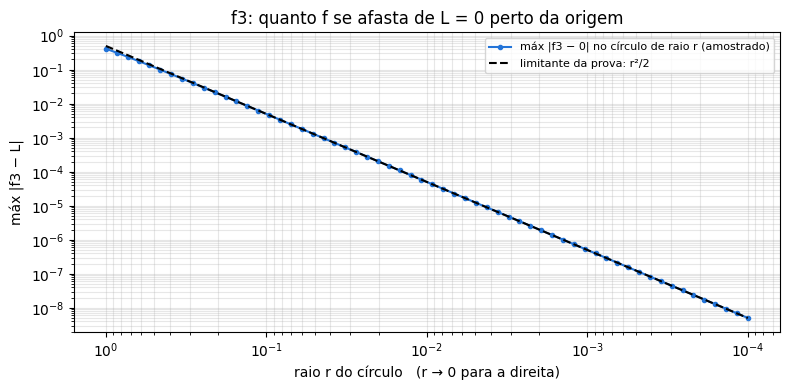


r²/2 − f3 = r**2*(sqrt(r**2 + 1) - 1)/(2*(sqrt(r**2 + 1) + 1))   (produto de fatores ≥ 0)
f3 − (√(r²+1) − 1) = 0
lim_{r→0} (√(r²+1) − 1) = 0


In [51]:
# 💻 f3: conferência do limitante 0 ≤ f3 ≤ r²/2
conferir_limitante('f3', L=0, limitante=lambda r: r**2 / 2, texto_limitante='r²/2')

# SymPy: a folga r²/2 − f3 é sempre ≥ 0, e a forma racionalizada coincide com f3
f3_polar = r_**2 / (sp.sqrt(r_**2 + 1) + 1)      # r_ = símbolo r > 0 (item 1)
print("\nr²/2 − f3 =", sp.factor(sp.simplify(r_**2 / 2 - f3_polar)), "  (produto de fatores ≥ 0)")
print("f3 − (√(r²+1) − 1) =", sp.simplify(f3_polar - (sp.sqrt(r_**2 + 1) - 1)))
print("lim_{r→0} (√(r²+1) − 1) =", sp.limit(sp.sqrt(r_**2 + 1) - 1, r_, 0))

In [52]:
# 💻 f3: verificador ε-δ (fator 1 = δ = √(2ε) da prova; com fator maior o disco passa a pegar pontos vermelhos)
# O valor f3(0,0) = 2 não interfere: a origem (bolinha aberta) está fora do disco furado.
verificador_eps_delta('f3', L=0, formula_delta=lambda e: np.sqrt(2 * e), texto_delta=r'\delta = \sqrt{2\varepsilon}')

### Conclusão do item 2

| Função | Limite em $(0,0)$ | Justificativa conclusiva |
|:---:|:---:|:---|
| $f_1$ | $0$ | confronto: $\lvert f_1\rvert \le \sqrt{x^2+y^2}$; ε-δ com $\delta = \varepsilon$ |
| $f_2$ | **não existe** | dois caminhos: eixo $x$ dá $0$, reta $y = x$ dá $\tfrac12$ |
| $f_3$ | $0$ | confronto: $0 \le f_3 \le \tfrac{x^2+y^2}{2}$ (ou $f_3 = \sqrt{x^2+y^2+1} - 1$, contínua); ε-δ com $\delta = \sqrt{2\varepsilon}$ |

Em nenhum dos três casos o valor atribuído $f(0,0)$ foi usado: o limite depende só dos pontos **próximos** da origem, nunca da origem em si.

---
## Item 3 – O mesmo valor em algumas trajetórias não prova que o limite existe

> **Enunciado:** Explique por que observar o mesmo valor ao longo de algumas trajetórias não prova que o limite existe.

**Como este item está organizado**

1. ✍️ **O argumento lógico:** o que a definição exige e por que a implicação "limite ⟹ caminhos" só vale num sentido.
2. **Dois contraexemplos**, o segundo enganando uma família de caminhos maior que o primeiro:

| Contraexemplo | Caminhos que concordam (todos dão 0) | Caminho que discorda |
|:---|:---|:---|
| $f_2 = \dfrac{xy}{x^2+y^2}$ (da própria questão) | os dois eixos e **todas** as parábolas | a reta $y = x$, que dá $\tfrac12$ |
| $g = \dfrac{x^2y}{x^4+y^2}$ | **todas** as retas | a parábola $y = x^2$, que dá $\tfrac12$ |

   Para cada um: ✍️ análise na mão e 💻 superfície com as trajetórias e tabela; para $g$, também a conferência simbólica.
3. **Conclusão do item.**

### O argumento lógico

#### Análise na mão ✍️

**1. O que a definição exige.** $\displaystyle\lim_{(x,y)\to(0,0)} f = L$ quer dizer que, para cada $\varepsilon > 0$, existe $\delta > 0$ tal que $|f(x,y) - L| < \varepsilon$ em **todos** os pontos do disco furado $0 < \sqrt{x^2+y^2} < \delta$.

Um caminho $\gamma(t)$ só passa por uma **curva** dentro desse disco. Uma lista de caminhos, mesmo infinita (todas as retas, por exemplo), cobre só uma parte dos pontos. Os pontos que ficam de fora podem ter valores bem diferentes de $L$.

**2. A implicação só vale num sentido.** No item 2 (passo 1 da $f_2$) provamos:

$$\lim_{(x,y)\to(0,0)} f = L \quad\Longrightarrow\quad f(\gamma(t)) \to L \text{ ao longo de } \textbf{todo} \text{ caminho } \gamma.$$

- **Contrapositiva (vale):** se dois caminhos dão valores diferentes, ou se algum caminho não tem limite, então o limite **não existe**. Foi assim que resolvemos a $f_2$.
- **Recíproca (não vale):** "os caminhos que testei dão $L$" **não** implica "o limite é $L$". Testamos alguns caminhos; a definição fala de **todos os pontos**. Pode haver um caminho, que não testamos, em que $f$ vai para outro valor.

**3. O que realmente prova um limite.** Uma estimativa que vale em **todos** os pontos perto da origem ao mesmo tempo, como no item 2:

$$|f_1(x,y)| \le \sqrt{x^2+y^2} \qquad\text{ou}\qquad 0 \le f_3(x,y) \le \frac{x^2+y^2}{2}.$$

As trajetórias do item 1 só **sugeriram** o candidato $L = 0$. Quem provou foram essas desigualdades, que usam só a distância à origem e **não dependem de caminho nenhum**.

**4. Resumo.**

| Observação | O que se pode concluir |
|:---|:---|
| dois caminhos com limites diferentes | ✅ o limite **não existe** (prova) |
| um caminho sem limite (por exemplo, oscilando) | ✅ o limite **não existe** (prova) |
| vários caminhos (até infinitos) com o mesmo valor $L$ | ⚠️ só que **se** o limite existir, ele vale $L$ (candidato, não prova) |
| desigualdade $\lvert f - L\rvert \le g(x,y)$ com $g \to 0$ | ✅ o limite **existe** e vale $L$ (prova) |

In [ ]:
# 💻 Configuração do item 3: o contraexemplo g
def g(x, y, valor_origem=None):
    """x²y/(x⁴+y²) fora da origem; 0 na origem."""
    x, y, _ = _preparar(x, y)
    v0 = VALOR_ORIGEM['g'] if valor_origem is None else valor_origem
    den = x**4 + y**2                     # só é 0 na origem
    return np.divide(x**2 * y, den, out=np.full_like(den, v0), where=den > 0)


# Registrando g, as ferramentas dos itens 1 e 2 passam a funcionar para ela sem código novo
VALOR_ORIGEM['g'] = 0.0
FUNCOES['g'] = g
EXPR['g'] = xs_**2 * ys_ / (xs_**4 + ys_**2)

print('g(0.1, 0.01) =', float(g(0.1, 0.01)), '  (ponto da parábola y = x²)')

### Contraexemplo 1: a própria $f_2 = \dfrac{xy}{x^2 + y^2}$

#### Análise na mão ✍️

Já fizemos as contas no item 1:

| Trajetória | $f_2$ ao longo dela | limite |
|:---|:---:|:---:|
| eixo $x$: $(t, 0)$ | $0$ | $0$ |
| eixo $y$: $(0, t)$ | $0$ | $0$ |
| parábola $y = kx^2$ (qualquer $k$) | $\dfrac{k\,t}{1 + k^2t^2}$ | $0$ |
| parábola $x = ky^2$ (qualquer $k$) | $\dfrac{k\,t}{k^2t^2 + 1}$ | $0$ |
| **reta $y = x$** | $\tfrac12$ | $\tfrac12$ |

Quem testasse só os eixos e as parábolas veria **infinitos caminhos** concordando em 0, e esse 0 ainda coincide com o valor atribuído $f_2(0,0) = 0$. A tentação de concluir "o limite é 0 e $f_2$ é contínua" seria grande, e a conclusão estaria **errada**: a reta $y = x$ dá $\tfrac12$, e o item 2 provou que o limite não existe.

**Por que as parábolas enganam:** elas chegam na origem **tangentes a um eixo**, ou seja, na direção $\theta \to 0$ ou $\theta \to \tfrac\pi2$. Como $f_2 = \tfrac{\sin 2\theta}{2}$ depende só da direção, todas elas "veem" o mesmo valor que os eixos.

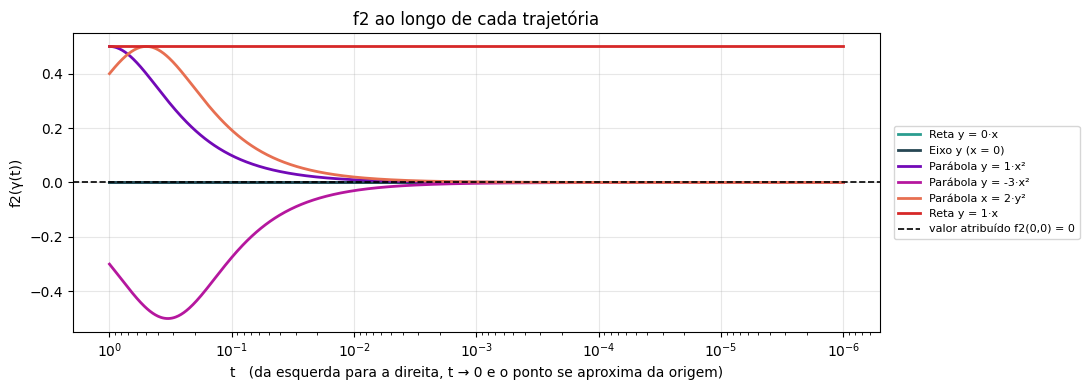

f2(γ(t)) para t -> 0:

trajetória                     t = 0.1      t = 0.01     t = 0.001    t = 0.0001     t = 1e-06
Reta y = 0·x                  0.000000      0.000000      0.000000      0.000000      0.000000
Eixo y (x = 0)                0.000000      0.000000      0.000000      0.000000      0.000000
Parábola y = 1·x²             0.099010      0.009999      0.001000      0.000100      0.000001
Parábola y = -3·x²           -0.275229     -0.029973     -0.003000     -0.000300     -0.000003
Parábola x = 2·y²             0.192308      0.019992      0.002000      0.000200      0.000002
Reta y = 1·x                  0.500000      0.500000      0.500000      0.500000      0.500000


In [54]:
# 💻 f2: eixos e parábolas concordam em 0; a reta y = x não (arraste para girar)
CASOS_3_F2 = [
    ('Reta y = m·x',      0.0,  '#2a9d8f'),     # eixo x
    ('Eixo y (x = 0)',    0,    '#264653'),
    ('Parábola y = k·x²', 1.0,  '#7209b7'),
    ('Parábola y = k·x²', -3.0, '#b5179e'),
    ('Parábola x = k·y²', 2.0,  '#e76f51'),
    ('Reta y = m·x',      1.0,  '#d62828'),     # o caminho que discorda
]
mostrar_trajetorias('f2', CASOS_3_F2, 'f2: eixos e parábolas dizem "0", a reta y = x diz "1/2"')

### Contraexemplo 2: $g(x,y) = \dfrac{x^2 y}{x^4 + y^2}$, com $g(0,0) = 0$: todas as retas concordam

#### Análise na mão ✍️

**Passo 1: todas as retas dão 0.** Com $x = t$, $y = mt$ e $m \ne 0$:

$$g(t,\, mt) = \frac{t^2 \cdot mt}{t^4 + m^2t^2} = \frac{m\,t^3}{t^2\,(t^2 + m^2)} = \frac{m\,t}{t^2 + m^2} \;\xrightarrow{\;t\to0\;}\; \frac{0}{m^2} = 0.$$

Os eixos também dão 0: $g(t, 0) = 0$ e $g(0, t) = 0$. **Toda reta** pela origem concorda com o valor 0, e são infinitas.

**Passo 2: a parábola $y = x^2$ discorda.**

$$g(t,\, t^2) = \frac{t^2 \cdot t^2}{t^4 + t^4} = \frac{t^4}{2t^4} = \frac12 \;\to\; \frac12 \ne 0.$$

Mais geralmente, $g(t,\, kt^2) = \dfrac{k\,t^4}{t^4 + k^2t^4} = \dfrac{k}{1 + k^2}$: cada parábola $y = kx^2$ é uma **curva de nível** de $g$. Elas fazem aqui o papel que as retas faziam na $f_2$.

**Conclusão:** pelo critério dos dois caminhos (item 2), eixo $x$ com 0 e parábola $y = x^2$ com $\tfrac12$, **o limite de $g$ em $(0,0)$ não existe**, apesar de todas as retas concordarem.

**Passo 3: a "crista" que toda reta atravessa.** Na reta $y = mx$ (com $m > 0$), a altura $\dfrac{m\,t}{t^2 + m^2}$ é 0 em $t = 0$, **sobe até $\tfrac12$** e depois volta a cair. Derivando em $t$:

$$\frac{d}{dt}\,\frac{m\,t}{t^2 + m^2} = \frac{m\,(m^2 - t^2)}{(t^2 + m^2)^2} = 0 \iff t = m, \qquad \text{altura máxima} = \frac{m \cdot m}{m^2 + m^2} = \frac12.$$

E o ponto $(m,\, m^2)$ é exatamente onde a reta $y = mx$ **cruza a parábola** $y = x^2$. A superfície tem uma **crista de altura $\tfrac12$** em cima da parábola. Toda reta passa por ela uma vez e depois desce até 0. Quanto menor o $m$, mais perto da origem fica esse cruzamento, mas ele **nunca desaparece**. Por isso, em **todo** disco em volta da origem, por menor que seja, há pontos com $g = \tfrac12$ (na crista) e com $g = 0$ (nos eixos). Pelo mesmo argumento do item 2 (passo 3 da $f_2$), nenhum $\delta$ funciona para $\varepsilon \le \tfrac14$.

**Passo 4: por que "toda direção dá 0" não basta.** Em polares,

$$g = \frac{r\,\cos^2\theta\,\sin\theta}{r^2\cos^4\theta + \sin^2\theta}.$$

Para cada direção $\theta$ **fixa** (com $\sin\theta \ne 0$), o denominador tende a $\sin^2\theta > 0$ e $g \to 0$. Isso é só uma reformulação de "toda reta dá 0". Mas a convergência **não é uniforme**: quando $\theta$ também se aproxima de 0 na medida certa, como acontece ao longo da parábola, o denominador fica tão pequeno quanto o numerador. Não existe limitante $g(r) \to 0$ que valha para todo $\theta$ ao mesmo tempo, que era o que fazia a prova da $f_1$ funcionar.

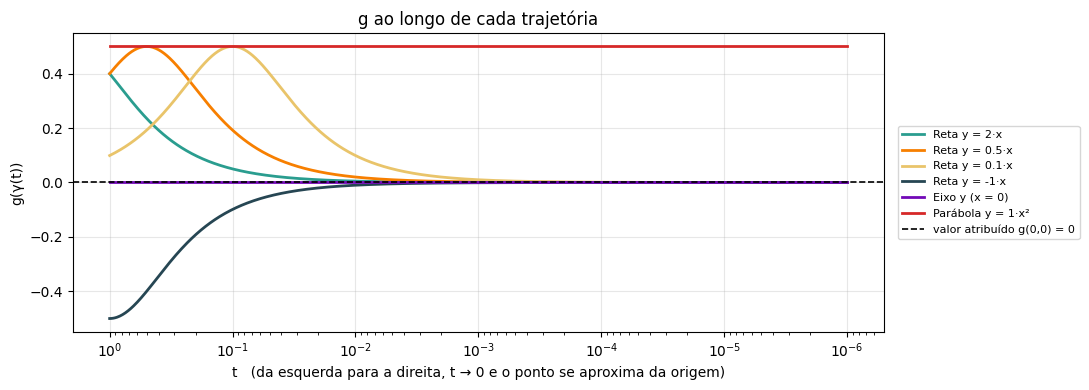

g(γ(t)) para t -> 0:

trajetória                     t = 0.1      t = 0.01     t = 0.001    t = 0.0001     t = 1e-06
Reta y = 2·x                  0.049875      0.005000      0.000500      0.000050      0.000000
Reta y = 0.5·x                0.192308      0.019992      0.002000      0.000200      0.000002
Reta y = 0.1·x                0.500000      0.099010      0.009999      0.001000      0.000010
Reta y = -1·x                -0.099010     -0.009999     -0.001000     -0.000100     -0.000001
Eixo y (x = 0)                0.000000      0.000000      0.000000      0.000000      0.000000
Parábola y = 1·x²             0.500000      0.500000      0.500000      0.500000      0.500000


In [55]:
# 💻 g: todas as retas vão a 0, a parábola y = x² fica na altura 1/2 (arraste para girar)
CASOS_G = [
    ('Reta y = m·x',       2.0,  '#2a9d8f'),
    ('Reta y = m·x',       0.5,  '#f77f00'),
    ('Reta y = m·x',       0.1,  '#e9c46a'),
    ('Reta y = m·x',      -1.0,  '#264653'),
    ('Eixo y (x = 0)',     0,    '#7209b7'),
    ('Parábola y = k·x²',  1.0,  '#d62828'),     # a crista: o caminho que discorda
]
mostrar_trajetorias('g', CASOS_G, 'g = x²y/(x⁴+y²): toda reta vai a 0, mas a parábola y = x² fica em 1/2')

In [ ]:
# 💻 g: conferência simbólica
# Na linha "Polares", o limite com θ FIXO é 0: é só outra forma de dizer "toda reta dá 0".
# Não prova nada, porque o limite de verdade precisa valer com θ variando junto com r (passo 4).
conferencia_simbolica('g')

### Conclusão do item 3

- A definição de limite fala de **todos os pontos** de um disco furado em volta da origem. Caminhos de uma família fixada (retas, parábolas, ...) cobrem só **alguns** desses pontos.
- Por isso, caminhos funcionam **num sentido só**:
  - dois caminhos com valores diferentes **provam** que o limite não existe ($f_2$, $g$);
  - muitos caminhos com o mesmo valor apenas **sugerem um candidato**.
- Os contraexemplos mostram que concordar numa família inteira de caminhos não basta:

| Função | Concordam em 0 | Discorda |
|:---:|:---|:---:|
| $f_2$ | eixos e todas as parábolas | reta $y = x$ $\to \tfrac12$ |
| $g$ | todas as retas | parábola $y = x^2$ $\to \tfrac12$ |

- O padrão continua: $\dfrac{x^n y}{x^{2n} + y^2}$ concorda em 0 ao longo de todas as curvas $y = kx^j$ com $j \ne n$, mas vale $\tfrac12$ ao longo de $y = x^n$. Seja qual for a família de caminhos **fixada** (retas, parábolas, polinômios até certo grau, ...), dá para construir uma função que concorda em todos eles e mesmo assim não tem limite. Só se **todo** caminho possível desse o mesmo valor é que o limite existiria, e isso não se verifica testando caminhos.
- Para provar que um limite **existe** é preciso uma estimativa que valha para todos os pontos ao mesmo tempo, como as desigualdades usadas para $f_1$ e $f_3$ no item 2.

---
## Item 4 – Limite × valor na origem: continuidade

> **Enunciado:** Compare o limite, quando existente, com o valor atribuído à função na origem; conclua sobre a continuidade.

**A definição.** $f$ é **contínua** em $(0,0)$ quando valem as **três** condições:

1. $f(0,0)$ **existe** (a função está definida na origem);
2. $\displaystyle\lim_{(x,y)\to(0,0)} f(x,y)$ **existe**;
3. os dois são **iguais**: $\displaystyle\lim_{(x,y)\to(0,0)} f(x,y) = f(0,0)$.

Em ε-δ: para todo $\varepsilon > 0$ existe $\delta > 0$ tal que $\sqrt{x^2+y^2} < \delta \implies |f(x,y) - f(0,0)| < \varepsilon$. É a definição de limite com $L = f(0,0)$, agora **sem** o "$0 <$". Na origem a desigualdade vale de graça, porque $|f(0,0) - f(0,0)| = 0$.

**Limite × continuidade.** O limite **ignora** a origem e olha só os pontos próximos (item 2). A continuidade é exatamente a **comparação** entre o que acontece perto da origem (o limite) e o que acontece na origem (o valor atribuído).

**Tipos de descontinuidade**

| Situação | Tipo | Dá para "consertar" mudando só $f(0,0)$? |
|:---|:---|:---|
| o limite existe, mas $\ne f(0,0)$ | **removível** | ✅ sim: basta redefinir $f(0,0) = $ limite |
| o limite não existe | **não removível** | ❌ não: o limite ignora $f(0,0)$, então nenhum valor resolve |

**Como este item está organizado**

1. ✍️ **Fora da origem:** por que a única dúvida é o ponto $(0,0)$.
2. 💻 **Configuração do item:** diagnóstico das três condições, distância ao valor da origem e superfície com o limite marcado.
3. **Para cada função:** ✍️ análise na mão das três condições e 💻 a conferência.
4. **Conclusão do item.**

**Convenção dos gráficos:** ponto **preto** = valor atribuído $(0,0,f(0,0))$; bolinha **aberta** = o limite $(0,0,L)$, quando existe; segmento **tracejado** = alturas que se acumulam na origem, quando o limite não existe.

### Fora da origem

#### Análise na mão ✍️

Em todo ponto $(x,y) \ne (0,0)$ as três funções são **contínuas**:
- $f_1 = \dfrac{x^2y}{x^2+y^2}$ e $f_2 = \dfrac{xy}{x^2+y^2}$ são quocientes de polinômios (contínuos) com denominador $x^2 + y^2 \ne 0$;
- $f_3 = \dfrac{x^2+y^2}{\sqrt{x^2+y^2+1}+1}$: o radicando é $\ge 1 > 0$, então a raiz é contínua, e o denominador é $\ge 2 \ne 0$. É um quociente de funções contínuas.

Logo a **única** questão de continuidade é o ponto $(0,0)$, justamente onde a fórmula não vale e o valor foi **atribuído** à parte.

In [ ]:
# 💻 Configuração do item 4: diagnóstico das três condições, distância ao valor da origem e superfície

# Resultados dos itens 2 e 3 (None = o limite não existe). Estes NÃO dependem de f(0,0).
LIMITE = {'f1': 0.0, 'f2': None, 'f3': 0.0}

# Quando o limite não existe: faixa de alturas que se acumulam perto da origem (para o desenho)
ACUMULO = {'f2': (-0.5, 0.5)}


def diagnostico(nome_f, valor_origem=None):
    """As três condições da continuidade em (0,0), usando o valor atribuído atual (ou o passado)."""
    v0 = VALOR_ORIGEM[nome_f] if valor_origem is None else valor_origem
    L = LIMITE[nome_f]
    if L is None:
        return dict(v0=v0, L=None, cond3=None, continua=False, falha='2 (o limite não existe)',
                    tipo='não removível: nenhum valor de f(0,0) resolve')
    if np.isclose(L, v0):
        return dict(v0=v0, L=L, cond3=True, continua=True, falha='—', tipo='—')
    return dict(v0=v0, L=L, cond3=False, continua=False, falha=f'3 (limite {L:g} ≠ f(0,0) = {v0:g})',
                tipo=f'removível: basta redefinir f(0,0) = {L:g}')


def tabela_continuidade(nomes, valores=None):
    """Tabela das três condições. valores = {nome: f(0,0)} opcional (o item 5 usa isso)."""
    valores = valores or {}
    linhas = ['| Função | (1) $f(0,0)$ | (2) limite em $(0,0)$ | (3) limite $= f(0,0)$? | Contínua em $(0,0)$? | Condição que falha | Tipo |',
              '|:---:|:---:|:---:|:---:|:---:|:---|:---|']
    for n in nomes:
        d = diagnostico(n, valores.get(n))
        lim = 'não existe' if d['L'] is None else f"${d['L']:g}$"
        c3 = '—' if d['cond3'] is None else ('✅' if d['cond3'] else '❌')
        nome_tex = f"${n[0]}_{n[1:]}$"                                   # 'f1' -> $f_1$
        linhas.append(f"| {nome_tex} | ${d['v0']:g}$ | {lim} | {c3} | {'✅ sim' if d['continua'] else '❌ não'} "
                      f"| {d['falha']} | {d['tipo']} |")
    display(Markdown('\n'.join(linhas)))


DELTAS = [1, 1e-1, 1e-2, 1e-3, 1e-4, 1e-6]


def distancia_ao_valor(nome_f, valor_origem=None):
    """Maior |f(x,y) − f(0,0)| no disco 0 < r < δ. Contínua <=> esse número vai a 0 quando δ -> 0."""
    v0 = VALOR_ORIGEM[nome_f] if valor_origem is None else valor_origem
    piores = [pior_ponto(nome_f, v0, d)[2] for d in DELTAS]
    print(f"Maior |{nome_f}(x,y) − {nome_f}(0,0)| no disco 0 < r < δ   (com {nome_f}(0,0) = {v0:g}):\n")
    print(f"{'δ':>10}{'maior distância':>18}")
    for d, p in zip(DELTAS, piores):
        print(f"{d:>10g}{p:>18.6g}")
    fim = piores[-1]
    print(f"\n-> quando δ -> 0, a maior distância {'vai a 0' if fim < 1e-5 else f'NÃO vai a 0 (fica perto de {fim:.3g})'}.")

    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.semilogx(DELTAS, piores, 'o-', color='#2374d8')
    ax.axhline(0, color='gray', lw=0.8)
    ax.invert_xaxis()
    ax.set(xlabel='raio δ do disco   (δ → 0 para a direita)', ylabel=f'máx |{nome_f} − {nome_f}(0,0)|',
           title=f'{nome_f}: o quanto os pontos próximos se afastam do valor na origem')
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


def superficie_continuidade(nome_f, titulo, valor_origem=None):
    """Superfície + valor atribuído (preto) + limite (bolinha aberta) ou faixa de acúmulo (tracejado)."""
    v0 = VALOR_ORIGEM[nome_f] if valor_origem is None else valor_origem
    tracos = [superficie_polar(nome_f),
              go.Scatter3d(x=[0], y=[0], z=[v0], mode='markers', marker=dict(color='black', size=6),
                           name=f'valor atribuído: {nome_f}(0,0) = {v0:g}')]
    L = LIMITE[nome_f]
    if L is not None:
        tracos.append(go.Scatter3d(x=[0], y=[0], z=[L], mode='markers',
                                   marker=dict(color='white', size=8, symbol='circle-open',
                                               line=dict(color='black', width=3)),
                                   name=f'limite em (0,0): {L:g}'))
    else:
        a, b = ACUMULO[nome_f]
        tracos.append(go.Scatter3d(x=[0, 0], y=[0, 0], z=[a, b], mode='lines',
                                   line=dict(color='black', width=4, dash='dash'),
                                   name=f'sem limite: alturas de {a:g} a {b:g} se acumulam'))
    mostrar_3d(tracos, titulo)

### $f_1(x,y) = \dfrac{x^2 y}{x^2 + y^2}$, com $f_1(0,0) = 0$

#### Análise na mão ✍️

1. **$f_1(0,0)$ existe:** vale $0$. ✅
2. **O limite existe:** pelo item 2, $\displaystyle\lim_{(x,y)\to(0,0)} f_1 = 0$, pelo confronto $|f_1(x,y)| \le \sqrt{x^2+y^2}$. ✅
3. **São iguais:** limite $= 0 = f_1(0,0)$. ✅

**Em ε-δ, direto:** como $f_1(0,0) = 0$, a desigualdade do item 2 vale **também na origem**:

$$|f_1(x,y) - f_1(0,0)| \le \sqrt{x^2 + y^2} \quad \text{para todo } (x,y).$$

Com $\delta = \varepsilon$, $\sqrt{x^2+y^2} < \delta$ implica $|f_1(x,y) - f_1(0,0)| < \varepsilon$.

**Geometricamente:** a superfície chega à origem pela altura 0, e o ponto atribuído $(0,0,0)$ está exatamente ali: nem buraco, nem salto.

$$\boxed{f_1 \text{ é contínua em } (0,0)} \qquad \text{e, junto com o que vimos fora da origem, em todo } \mathbb{R}^2.$$

Maior |f1(x,y) − f1(0,0)| no disco 0 < r < δ   (com f1(0,0) = 0):

         δ   maior distância
         1          0.384881
       0.1         0.0384881
      0.01        0.00384881
     0.001       0.000384881
    0.0001       3.84881e-05
     1e-06       3.84881e-07

-> quando δ -> 0, a maior distância vai a 0.


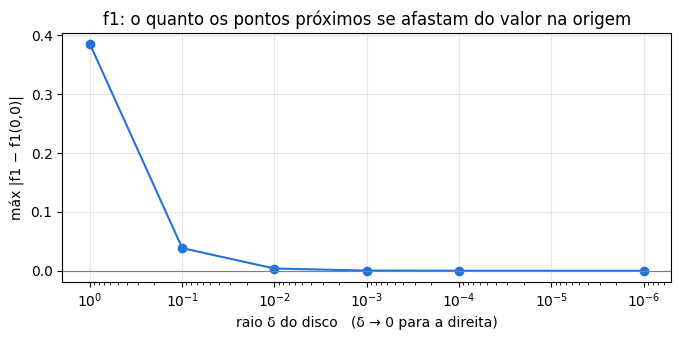

In [61]:
# 💻 f1: valor atribuído e limite coincidem (arraste para girar)
superficie_continuidade('f1', 'f1: o limite (bolinha aberta) e f1(0,0) (ponto preto) coincidem em z = 0')
distancia_ao_valor('f1')

### $f_2(x,y) = \dfrac{xy}{x^2 + y^2}$, com $f_2(0,0) = 0$

#### Análise na mão ✍️

1. **$f_2(0,0)$ existe:** vale $0$. ✅
2. **O limite existe?** Não. Pelo item 2, o eixo $x$ dá $0$ e a reta $y = x$ dá $\tfrac12$. ❌
3. Não há o que comparar: falta o limite.

$$\boxed{f_2 \text{ não é contínua em } (0,0)}$$

**A descontinuidade é não removível.** Suponha que trocássemos o valor atribuído por um número $c$ qualquer. O limite **não muda**, porque ele não olha a origem: continua não existindo, já que as duas retas continuam discordando. A condição 2 continua falhando, para **todo** $c$.

**Em ε-δ:** perto da origem há pontos com $f_2 = \tfrac12$ (reta $y = x$) e com $f_2 = -\tfrac12$ (reta $y = -x$). Para qualquer $c$, pelo menos um deles fica a distância $\ge \tfrac12$ de $c$ (item 2, passo 3). Com $\varepsilon = \tfrac12$, nenhum $\delta$ funciona.

**Geometricamente:** todas as alturas de $-\tfrac12$ a $\tfrac12$ "chegam" ao eixo $z$ (segmento tracejado). Nenhum ponto isolado consegue "fechar" uma superfície que chega à origem em infinitas alturas diferentes.

Maior |f2(x,y) − f2(0,0)| no disco 0 < r < δ   (com f2(0,0) = 0):

         δ   maior distância
         1               0.5
       0.1               0.5
      0.01               0.5
     0.001               0.5
    0.0001               0.5
     1e-06               0.5

-> quando δ -> 0, a maior distância NÃO vai a 0 (fica perto de 0.5).


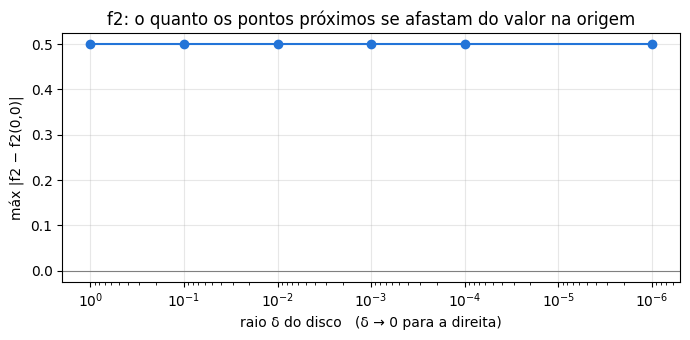

In [62]:
# 💻 f2: não há limite para comparar com f2(0,0) (arraste para girar)
superficie_continuidade('f2', 'f2: sem limite, nenhum valor na origem fecha a superfície')
distancia_ao_valor('f2')

### $f_3(x,y) = \dfrac{x^2 + y^2}{\sqrt{x^2 + y^2 + 1} + 1}$, com $f_3(0,0) = 2$

#### Análise na mão ✍️

1. **$f_3(0,0)$ existe:** vale $2$. ✅
2. **O limite existe:** pelo item 2, $\displaystyle\lim_{(x,y)\to(0,0)} f_3 = 0$. ✅
3. **São iguais?** Limite $= 0 \ne 2 = f_3(0,0)$. ❌

$$\boxed{f_3 \text{ não é contínua em } (0,0)}$$

**Em ε-δ:** perto da origem, $f_3(x,y) \approx 0$, então $|f_3(x,y) - f_3(0,0)| = |f_3(x,y) - 2| \approx 2$. Com $\varepsilon = 1$, por exemplo, nenhum $\delta$ funciona: todo disco em volta da origem tem pontos (todos, menos a própria origem) a distância perto de 2 do valor atribuído.

**A descontinuidade é removível.** O limite existe, só o valor atribuído está "errado". Definindo

$$\tilde f_3(x,y) = \begin{cases} f_3(x,y), & (x,y) \ne (0,0) \\ 0, & (x,y) = (0,0) \end{cases}$$

temos $\tilde f_3(x,y) = \sqrt{x^2+y^2+1} - 1$ em **todo** o plano. Fora da origem isso vem da racionalização do item 1; na origem, os dois lados valem 0. Essa função é contínua em todo o plano. Mudar **só** $f_3(0,0)$ de 2 para 0 resolve. É isso que o item 5 vai mostrar interativamente.

**Geometricamente:** a tigela $z = \sqrt{x^2+y^2+1} - 1$ chega até $(0,0,0)$ (bolinha aberta), mas o ponto do gráfico na origem foi colocado em $(0,0,2)$ (ponto preto), **flutuando** acima dela. É um "buraco" na superfície mais um ponto fora do lugar.

Maior |f3(x,y) − f3(0,0)| no disco 0 < r < δ   (com f3(0,0) = 2):

         δ   maior distância
         1                 2
       0.1                 2
      0.01                 2
     0.001                 2
    0.0001                 2
     1e-06                 2

-> quando δ -> 0, a maior distância NÃO vai a 0 (fica perto de 2).


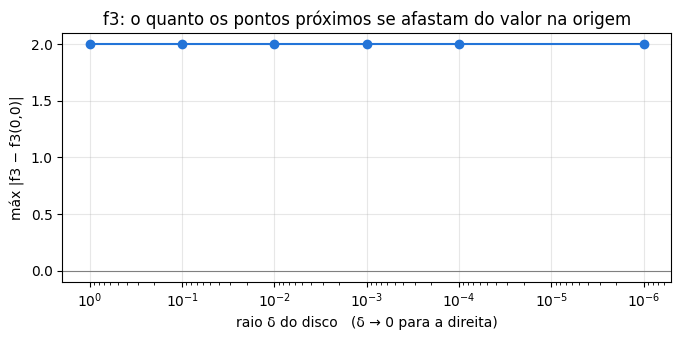

In [63]:
# 💻 f3: o limite (0) e o valor atribuído (2) estão separados (arraste para girar)
superficie_continuidade('f3', 'f3: limite 0 (bolinha aberta) ≠ f3(0,0) = 2 (ponto preto)')
distancia_ao_valor('f3')

### Conclusão do item 4

In [66]:
# 💻 Resumo: as três condições da continuidade em (0,0)
tabela_continuidade(['f1', 'f2', 'f3'])

| Função | (1) $f(0,0)$ | (2) limite em $(0,0)$ | (3) limite $= f(0,0)$? | Contínua em $(0,0)$? | Condição que falha | Tipo |
|:---:|:---:|:---:|:---:|:---:|:---|:---|
| $f_1$ | $0$ | $0$ | ✅ | ✅ sim | — | — |
| $f_2$ | $0$ | não existe | — | ❌ não | 2 (o limite não existe) | não removível: nenhum valor de f(0,0) resolve |
| $f_3$ | $2$ | $0$ | ❌ | ❌ não | 3 (limite 0 ≠ f(0,0) = 2) | removível: basta redefinir f(0,0) = 0 |

- **$f_1$** é contínua em $(0,0)$: o limite existe e coincide com o valor atribuído.
- **$f_2$** não é contínua: o limite não existe. A descontinuidade é **não removível**, e nenhum valor de $f_2(0,0)$ a conserta.
- **$f_3$** não é contínua: o limite existe ($0$), mas é diferente do valor atribuído ($2$). A descontinuidade é **removível**: redefinindo $f_3(0,0) = 0$, ela fica contínua.

Os três casos mostram a diferença da pergunta orientadora: **existir valor** ($f(0,0)$ definido, nas três funções), **existir limite** ($f_1$ e $f_3$) e **haver continuidade** (só $f_1$, onde as duas coisas existem **e** coincidem).

---
## Item 5 – Controle que altera somente $f(0,0)$

> **Enunciado:** Implemente um controle que altere somente $f(0,0)$ e mostre o efeito sobre a continuidade, sem modificar o limite.

**Como este item está organizado**

1. ✍️ **Análise na mão:** por que mudar $f(0,0)$ **não pode** mudar o limite e quando a continuidade aparece ou some.
2. 💻 **Configuração do item:** o painel interativo.
3. 💻 **Controle interativo:** escolha a função e o valor $c = f(0,0)$.
4. 💻 **Varredura:** vários valores de $c$ lado a lado (sem widgets, para o relatório).
5. **Conclusão do item.**

**Como o controle funciona no código:** as funções $f_1$, $f_2$, $f_3$ aceitam `valor_origem=c`, que troca **apenas** o valor devolvido no ponto $(0,0)$. A fórmula usada nos outros pontos é a mesma. O dicionário `VALOR_ORIGEM` **não é alterado**, então os outros itens continuam usando os valores do enunciado.

#### Análise na mão ✍️

**Passo 1: o que o controle muda.** Para cada número $c$, considere

$$f_c(x,y) = \begin{cases} \text{a fórmula da função}, & (x,y) \ne (0,0) \\ c, & (x,y) = (0,0). \end{cases}$$

Duas versões $f_c$ e $f_{c'}$ são **iguais em todos os pontos, menos na origem**.

**Passo 2: o limite não depende de $c$.** A definição de limite só usa pontos com $0 < \sqrt{x^2+y^2} < \delta$, e nesses pontos $f_c = f_{c'}$. A afirmação

$$\text{"para todo } \varepsilon > 0 \text{ existe } \delta > 0 \text{ tal que } 0 < \sqrt{x^2+y^2} < \delta \implies |f_c(x,y) - L| < \varepsilon\text{"}$$

é **literalmente a mesma** para qualquer $c$. Logo o limite de $f_c$ existe para um $c$ se e somente se existe para todos, e tem sempre o mesmo valor. Isso é uma **demonstração**, não uma observação numérica: o controle não tem como mudar o limite.

**Passo 3: a continuidade depende de $c$.** $f_c$ é contínua em $(0,0)$ se e somente se o limite $L$ existe **e** $L = c$. Quando $L$ existe, perto da origem $f_c(x,y) \approx L$, então

$$|f_c(x,y) - c| \;\to\; |L - c| \qquad \text{quando } (x,y) \to (0,0),\ (x,y) \ne (0,0).$$

Essa distância vai a 0 **só quando $c = L$**. Para qualquer outro $c$, ela fica perto de $|L - c| > 0$ e a continuidade falha.

**Passo 4: o efeito em cada função.**

| Função | Limite (fixo) | Contínua para... | Valor do enunciado | O que o controle mostra |
|:---:|:---:|:---:|:---:|:---|
| $f_1$ | $0$ | só $c = 0$ | $0$ ✅ | qualquer $c \ne 0$ **cria** uma descontinuidade removível |
| $f_2$ | não existe | **nenhum** $c$ | $0$ ❌ | nenhum valor conserta: descontinuidade não removível |
| $f_3$ | $0$ | só $c = 0$ | $2$ ❌ | levar $c$ de $2$ para $0$ **remove** a descontinuidade |

**Geometricamente:** o controle move só o ponto preto $(0,0,c)$ para cima e para baixo. A superfície e a bolinha aberta do limite **não saem do lugar**. A função é contínua exatamente quando o ponto preto **se encaixa** na bolinha aberta. Na $f_2$ não há bolinha onde encaixar, só a faixa tracejada de alturas.

In [67]:
# 💻 Configuração do item 5: painel que altera somente f(0,0)
T_COMPARACAO = [1e-3, 1e-6]
TRAJ_COMPARACAO = [('Reta y = m·x', 0.0), ('Reta y = m·x', 1.0), ('Parábola y = k·x²', 1.0), ('Espiral (r = t)', 0)]


def comparacao_antes_depois(nome_f, c):
    """Valores de f perto da origem com o valor do enunciado e com o novo c: idênticos fora da origem."""
    c0 = VALOR_ORIGEM[nome_f]
    f = FUNCOES[nome_f]
    linhas = [f'| Ponto | ${nome_f}$ com $f(0,0) = {c0:g}$ (enunciado) | ${nome_f}$ com $f(0,0) = {c:g}$ (controle) | mudou? |',
              '|:---|:---:|:---:|:---:|']
    for tr, p in TRAJ_COMPARACAO:
        gamma = TRAJETORIAS[tr][0]
        for t0 in T_COMPARACAO:
            x0, y0 = (float(v) for v in np.broadcast_arrays(*gamma(np.array(t0), p)))
            a, b = float(f(x0, y0)), float(f(x0, y0, valor_origem=c))
            linhas.append(f'| {rotulo(tr, p)}, t = {t0:g} | {a:.6g} | {b:.6g} | {"sim" if a != b else "não"} |')
    a, b = float(f(0, 0)), float(f(0, 0, valor_origem=c))
    linhas.append(f'| **origem (0, 0)** | **{a:g}** | **{b:g}** | **{"sim" if a != b else "não"}** |')
    display(Markdown('\n'.join(linhas)))


def distancias_ao_valor(nome_f, c):
    """Maior |f − c| em discos pequenos, comparado com o previsto |L − c|."""
    L = LIMITE[nome_f]
    previsto = 'não se aplica (sem limite)' if L is None else f'{abs(L - c):g}'
    linhas = [f'| δ | maior $\\lvert {nome_f} - c\\rvert$ em $0 < r < \\delta$ | previsto pela análise: $\\lvert L - c\\rvert$ |',
              '|:---:|:---:|:---:|']
    for d in [1e-1, 1e-3, 1e-6]:
        linhas.append(f'| {d:g} | {pior_ponto(nome_f, c, d)[2]:.6g} | {previsto} |')
    display(Markdown('\n'.join(linhas)))


def painel_valor_origem():
    estilo = {'description_width': 'initial'}
    funcao = widgets.Dropdown(options=[('f1 = x²y/(x²+y²)', 'f1'), ('f2 = xy/(x²+y²)', 'f2'),
                                       ('f3 = (x²+y²)/(√(x²+y²+1)+1)', 'f3')],
                              value='f3', description='Função:', layout=widgets.Layout(width='360px'))
    c = widgets.FloatSlider(value=VALOR_ORIGEM['f3'], min=-1, max=3, step=0.05, description='c = f(0,0):',
                            style=estilo, continuous_update=False, readout_format='.2f',
                            layout=widgets.Layout(width='420px'))
    b_enunciado = widgets.Button(description='valor do enunciado', icon='undo')
    b_limite = widgets.Button(description='valor do limite', icon='check', button_style='success')
    saida = widgets.Output()

    def atualizar(*_):
        nome, v = funcao.value, c.value
        L = LIMITE[nome]
        b_limite.disabled = L is None
        d = diagnostico(nome, v)
        with saida:
            clear_output(wait=True)
            superficie_continuidade(nome, f'{nome} com f(0,0) = {v:g}: só o ponto preto se move', valor_origem=v)
            if d['continua']:
                msg = f'✅ **c = {v:g} = limite**: o ponto preto se encaixa na bolinha aberta e **{nome} é contínua** em (0,0).'
            elif L is None:
                msg = (f'❌ **{nome} não é contínua** em (0,0) com c = {v:g}, e **nenhum** c resolve: '
                       'o limite não existe e não depende de c.')
            else:
                msg = (f'❌ **{nome} não é contínua** em (0,0): o limite continua {L:g}, mas c = {v:g} ≠ {L:g}. '
                       f'Descontinuidade **removível**: clique em "valor do limite" (c = {L:g}).')
            display(Markdown(msg))
            display(Markdown('**As três condições**'))
            tabela_continuidade([nome], {nome: v})
            display(Markdown('**O limite não mudou: a função só mudou na origem**'))
            comparacao_antes_depois(nome, v)
            display(Markdown('**Distância ao valor da origem perto de (0,0)**'))
            distancias_ao_valor(nome, v)

    def trocar_funcao(*_):
        if c.value == VALOR_ORIGEM[funcao.value]:
            atualizar()                      # o slider não muda, então atualiza direto
        else:
            c.value = VALOR_ORIGEM[funcao.value]   # dispara atualizar() pelo observe do slider

    funcao.observe(trocar_funcao, names='value')
    c.observe(atualizar, names='value')
    b_enunciado.on_click(lambda _: setattr(c, 'value', VALOR_ORIGEM[funcao.value]))
    b_limite.on_click(lambda _: setattr(c, 'value', LIMITE[funcao.value]))
    atualizar()
    display(widgets.VBox([widgets.HBox([funcao, c]), widgets.HBox([b_enunciado, b_limite]), saida]))

In [68]:
# 💻 Controle interativo: escolha a função e mova c = f(0,0). A superfície e o limite não mudam.
painel_valor_origem()

In [69]:
# 💻 Varredura (sem widgets, para o relatório): a mesma conclusão para vários valores de c
for c in [-1.0, 0.0, 0.5, 2.0]:
    display(Markdown(f'**c = f(0,0) = {c:g}** (o mesmo valor nas três funções)'))
    tabela_continuidade(['f1', 'f2', 'f3'], {n: c for n in ('f1', 'f2', 'f3')})

**c = f(0,0) = -1** (o mesmo valor nas três funções)

| Função | (1) $f(0,0)$ | (2) limite em $(0,0)$ | (3) limite $= f(0,0)$? | Contínua em $(0,0)$? | Condição que falha | Tipo |
|:---:|:---:|:---:|:---:|:---:|:---|:---|
| $f_1$ | $-1$ | $0$ | ❌ | ❌ não | 3 (limite 0 ≠ f(0,0) = -1) | removível: basta redefinir f(0,0) = 0 |
| $f_2$ | $-1$ | não existe | — | ❌ não | 2 (o limite não existe) | não removível: nenhum valor de f(0,0) resolve |
| $f_3$ | $-1$ | $0$ | ❌ | ❌ não | 3 (limite 0 ≠ f(0,0) = -1) | removível: basta redefinir f(0,0) = 0 |

**c = f(0,0) = 0** (o mesmo valor nas três funções)

| Função | (1) $f(0,0)$ | (2) limite em $(0,0)$ | (3) limite $= f(0,0)$? | Contínua em $(0,0)$? | Condição que falha | Tipo |
|:---:|:---:|:---:|:---:|:---:|:---|:---|
| $f_1$ | $0$ | $0$ | ✅ | ✅ sim | — | — |
| $f_2$ | $0$ | não existe | — | ❌ não | 2 (o limite não existe) | não removível: nenhum valor de f(0,0) resolve |
| $f_3$ | $0$ | $0$ | ✅ | ✅ sim | — | — |

**c = f(0,0) = 0.5** (o mesmo valor nas três funções)

| Função | (1) $f(0,0)$ | (2) limite em $(0,0)$ | (3) limite $= f(0,0)$? | Contínua em $(0,0)$? | Condição que falha | Tipo |
|:---:|:---:|:---:|:---:|:---:|:---|:---|
| $f_1$ | $0.5$ | $0$ | ❌ | ❌ não | 3 (limite 0 ≠ f(0,0) = 0.5) | removível: basta redefinir f(0,0) = 0 |
| $f_2$ | $0.5$ | não existe | — | ❌ não | 2 (o limite não existe) | não removível: nenhum valor de f(0,0) resolve |
| $f_3$ | $0.5$ | $0$ | ❌ | ❌ não | 3 (limite 0 ≠ f(0,0) = 0.5) | removível: basta redefinir f(0,0) = 0 |

**c = f(0,0) = 2** (o mesmo valor nas três funções)

| Função | (1) $f(0,0)$ | (2) limite em $(0,0)$ | (3) limite $= f(0,0)$? | Contínua em $(0,0)$? | Condição que falha | Tipo |
|:---:|:---:|:---:|:---:|:---:|:---|:---|
| $f_1$ | $2$ | $0$ | ❌ | ❌ não | 3 (limite 0 ≠ f(0,0) = 2) | removível: basta redefinir f(0,0) = 0 |
| $f_2$ | $2$ | não existe | — | ❌ não | 2 (o limite não existe) | não removível: nenhum valor de f(0,0) resolve |
| $f_3$ | $2$ | $0$ | ❌ | ❌ não | 3 (limite 0 ≠ f(0,0) = 2) | removível: basta redefinir f(0,0) = 0 |

### Conclusão do item 5

- O controle muda a função em **um único ponto**. Como a definição de limite não usa esse ponto, o limite **não muda**. Isso foi demonstrado no passo 2, e a tabela do painel mostra que os valores fora da origem não mudam.
- A continuidade **depende** de $c$: ela vale exatamente quando o ponto $(0,0,c)$ coincide com o limite.
  - $f_1$: contínua só com $c = 0$, que é o valor do enunciado. Qualquer outro $c$ cria uma descontinuidade removível.
  - $f_3$: contínua só com $c = 0$. O valor do enunciado ($c = 2$) a deixa descontínua, e mudar só esse valor a conserta.
  - $f_2$: descontínua para **todo** $c$. Quando o limite não existe, mexer no valor da origem não resolve.

---
## Pergunta orientadora

> **Qual é a diferença entre existir limite, existir valor da função e haver continuidade?**

São três perguntas **diferentes**, sobre partes diferentes da função:

| Conceito | Pergunta que responde | Olha para | Depende de $f(0,0)$? |
|:---|:---|:---|:---:|
| **existir valor** $f(0,0)$ | a função está **definida** na origem? | só o ponto $(0,0)$ | é o próprio $f(0,0)$ |
| **existir limite** $\displaystyle\lim_{(x,y)\to(0,0)} f$ | os valores **perto** da origem se aproximam de um único número $L$, por qualquer caminho? | os pontos com $0 < \sqrt{x^2+y^2} < \delta$, **nunca** a origem | **não** (itens 2 e 5) |
| **haver continuidade** em $(0,0)$ | o valor **na** origem é o que os pontos **perto** dela indicam? | as duas coisas juntas: exige que ambas existam **e** $L = f(0,0)$ | **sim** |

**As três situações apareceram nesta questão:**

- **Valor e limite existem e coincidem → contínua:** $f_1$, com $f_1(0,0) = 0 = \lim f_1$.
- **Valor e limite existem, mas são diferentes → descontínua (removível):** $f_3$, com $f_3(0,0) = 2$ e $\lim f_3 = 0$. Basta trocar o valor.
- **Valor existe, mas o limite não → descontínua (não removível):** $f_2$, com $f_2(0,0) = 0$ e trajetórias discordando ($0$ no eixo $x$, $\tfrac12$ na reta $y = x$). Nenhum valor resolve.
- E o limite pode existir **sem que exista valor**: a fórmula $\dfrac{x^2+y^2}{\sqrt{x^2+y^2+1}+1}$ sozinha nem está definida em $(0,0)$, porque ninguém atribuiu valor, e mesmo assim o limite é 0.

**Duas lições de método:**

1. Para provar que um limite **existe**, é preciso uma estimativa que valha em **todos** os pontos perto da origem (confronto, ε-δ), como para $f_1$ e $f_3$ no item 2. Observar o mesmo valor em algumas trajetórias, ou em infinitas, não basta (item 3: $f_2$ e $g$).
2. Para provar que um limite **não existe**, basta encontrar **dois caminhos** com limites diferentes, como para $f_2$.

**Resumindo:** o **valor** é um dado sobre um ponto; o **limite** é um dado sobre a vizinhança, sem o ponto; a **continuidade** é a concordância entre os dois.